<a href="https://colab.research.google.com/github/OJB-Quantum/Notebooks-for-Ideas/blob/main/Nanocryotron_Scikit_FEM_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authored by Onri Jay Benally (2026)

Open Access (CC-BY-4.0)

# Nanocryotron

## Physical model and parameters

The sheet-current vector $\mathbf K$ has units of amperes per metre, the scalar electric potential $\phi$ has units of volts, and the sheet inductance $L_\square$ has units of henries per square. Charge continuity constrains the current throughout the traced device, while resistive sheet heating directly supplies energy to the electron system. The load and series inductor form an explicit external circuit whose channel current is $I_\mathrm{ch}$ and whose imposed bias is $I_\mathrm b$.

$$
\mathbf E=-\nabla\phi=L_\square\frac{\partial\mathbf K}{\partial t}+R_\square f\mathbf K,\qquad\nabla\cdot\mathbf K=0
$$

$$
C_\mathrm e d\frac{\partial T_\mathrm e}{\partial t}=\nabla\cdot(\kappa_\mathrm e d\nabla T_\mathrm e)-G_\mathrm{ep}d(T_\mathrm e-T_\mathrm p)+R_\square f|\mathbf K|^2
$$

$$
C_\mathrm p d\frac{\partial T_\mathrm p}{\partial t}=\nabla\cdot(\kappa_\mathrm p d\nabla T_\mathrm p)+G_\mathrm{ep}d(T_\mathrm e-T_\mathrm p)-\frac{C_\mathrm p d}{\tau_\mathrm{esc}}(T_\mathrm p-T_\mathrm b)
$$

$$
L_\mathrm{ext}\frac{\mathrm d I_\mathrm{ch}}{\mathrm dt}=R_\mathrm L(I_\mathrm b-I_\mathrm{ch})-\phi_\mathrm d,\qquad V_\mathrm{out}=R_\mathrm L(I_\mathrm b-I_\mathrm{ch})
$$

Here, $d$ is film thickness, $f$ is the local resistive fraction between zero and one, and $\phi_\mathrm d$ is the drain contact potential relative to the grounded source. The gate injects its specified current, each terminal is equipotential, the other electrical boundaries are insulating, and all three thermal contacts remain at the bath temperature. Other film edges are thermally insulating, while phonon escape removes heat across the film/substrate interface.

| Symbol or acronym | Meaning and units |
|---|---|
| nTron; SEM; FEM; PHIDL | Nanocryotron; scanning electron micrograph; finite element method; PHIDL Python layout and geometry library |
| NbN; CPU; GPU; cuDSS | Niobium nitride; central processing unit; graphics processing unit; NVIDIA CUDA direct sparse solver library |
| $\mathbf E,\phi,\mathbf K$ | Electric field, V/m; potential, V; sheet current, A/m |
| $R_\square,L_\square,d$ | Normal sheet resistance, ohms/square; sheet kinetic inductance, H/square; thickness, m |
| $T_\mathrm e,T_\mathrm p,T_\mathrm b,T_\mathrm c$ | Electron, phonon, bath, and critical temperatures, K |
| $C_\mathrm e,C_\mathrm p$ | Volumetric heat capacities, J/(m³ K) |
| $\kappa_\mathrm e,\kappa_\mathrm p$ | Electron and phonon thermal conductivities, W/(m K) |
| $G_\mathrm{ep},\tau_\mathrm{esc}$ | Electron-phonon exchange coefficient, W/(m³ K); phonon escape time, s |
| $I_\mathrm b,I_\mathrm{ch},R_\mathrm L,L_\mathrm{ext}$ | Bias and channel currents, A; load resistance, ohms; external series inductance, H |
| $J_\mathrm c,K_\mathrm c$ | Critical volume current density, A/m²; critical sheet current density $J_\mathrm c d$, A/m |
| $\gamma,\alpha,D_\mathrm p,L_0$ | Electron and phonon heat-capacity coefficients; phonon diffusivity, m²/s; Lorenz number, W ohm/K² |
| $\hbar,k_\mathrm B,\Delta_0$ | Reduced Planck constant; Boltzmann constant; zero-temperature gap, J |

The baseline film uses the original paper's approximate $d=10$ nm, $T_\mathrm c=12.6$ K, $R_\square=285$ ohms/square, and $J_\mathrm c=6.6$ megaamperes per square centimetre [1]. This notebook interprets the reported current density as a bath-temperature threshold and derives the bias from the computed current-crowding limit. The shape is traced from Figure 1b, while the approximately 15 nm choke supplies a nominal target where a few image pixels span the junction.

Effective coefficients follow $C_\mathrm e=\gamma T_\mathrm e$, $C_\mathrm p=\alpha T_\mathrm p^3$, $\kappa_\mathrm e=L_0T_\mathrm e/(R_\square d)$, and $\kappa_\mathrm p=C_\mathrm pD_\mathrm p$. The coefficients $\gamma=240$ J/(m³ K²), $\alpha=1.03$ J/(m³ K⁴), $D_\mathrm p=0.33$ cm²/s, and $\tau_\mathrm{esc}=40$ ps follow the representative NbN model in [2]. The editable choice $\tau_\mathrm{ep}(T_\mathrm c)=10$ ps defines $G_\mathrm{ep}=\gamma T_\mathrm c[(T_\mathrm e+T_\mathrm p)/(2T_\mathrm c)]^4/\tau_\mathrm{ep}(T_\mathrm c)$ and is an assumed thermal parameter.

The critical-current approximation used in [6] is normalized so that its value at the bath equals the selected $J_\mathrm c$. Two logistic functions provide a thermal transition of width 0.15 K and a current transition of width $0.008J_\mathrm c(T_\mathrm b)d$; these editable widths regularize switching and require time-step checks. Their combination is $f=1-(1-f_T)(1-f_I)$, where $f_T$ switches around $T_\mathrm c$ and $f_I$ switches around $K_\mathrm c(T_\mathrm e)$.

$$
J_\mathrm c(T)=J_\mathrm c(T_\mathrm b)\frac{[1-(T/T_\mathrm c)^2]^{3/2}[1+(T/T_\mathrm c)^2]^{1/2}}{[1-(T_\mathrm b/T_\mathrm c)^2]^{3/2}[1+(T_\mathrm b/T_\mathrm c)^2]^{1/2}},\qquad 0\leq T<T_\mathrm c
$$

Above $T_\mathrm c$, the critical current is zero. The low-current estimate $L_\square\simeq\hbar R_\square/(\pi\Delta_0)$ uses $\Delta_0=1.764k_\mathrm BT_\mathrm c$ in the dirty, weak-coupling, low-temperature approximation and gives roughly 31 pH/square. The fourfold comparison changes **only** $L_\square$ to isolate its electrical effect, while a real material change also changes critical current and thermal properties [3].

## References

1. McCaughan, A.N. and Berggren, K.K. (2014) ‘A superconducting-nanowire three-terminal electrothermal device’, *Nano Letters*, 14(10), pp. 5748–5753. https://doi.org/10.1021/nl502629x

2. Simon, A., Foster, R., Medeiros, O., Castellani, M., Batson, E. and Berggren, K.K. (2025) ‘Characterizing and modeling the influence of geometry on the performance of superconducting nanowire cryotrons’, *IEEE Transactions on Applied Superconductivity*, 35(5), pp. 1–5. https://doi.org/10.1109/TASC.2024.3521894

3. Kerman, A.J., Dauler, E.A., Keicher, W.E., Yang, J.K.W., Berggren, K.K., Gol’tsman, G. and Voronov, B. (2006) ‘Kinetic-inductance-limited reset time of superconducting nanowire photon counters’, *Applied Physics Letters*, 88, 111116. https://doi.org/10.1063/1.2183810

4. Gustafsson, T. and McBain, G.D. (2020) ‘scikit-fem: A Python package for finite element assembly’, *Journal of Open Source Software*, 5(52), 2369. https://doi.org/10.21105/joss.02369

5. Yasukawa, N., Nishio, T. and Mawatari, Y. (2024) ‘Ginzburg–Landau simulations of three-terminal operation of a superconducting nanowire cryotron’, *Superconductor Science and Technology*, 37(6), 065013. https://doi.org/10.1088/1361-6668/ad44e4

6. Zheng, K. et al. (2019) ‘Characterize the switching performance of a superconducting nanowire cryotron for reading superconducting nanowire single photon detectors’, *Scientific Reports*, 9, 16345. https://doi.org/10.1038/s41598-019-52874-3

7. McCaughan, A.N. et al. (2021) ‘PHIDL: Python-based layout and geometry creation for nanolithography’, *Journal of Vacuum Science & Technology B*, 39, 062601. https://doi.org/10.1116/6.0001203

Software documentation: [scikit-FEM](https://scikit-fem.readthedocs.io/en/stable/), [PHIDL](https://phidl.readthedocs.io/en/latest/), and [Triangle](https://rufat.be/triangle/).

In [ ]:
import sys

!CC=gcc CXX=g++ uv pip install --system --python {sys.executable} \
    scikit-fem==12.0.2 \
    phidl==1.7.2 \
    gdspy==1.6.13 \
    triangle==20250106 \
    "numpy>=1.26,<3" \
    "scipy>=1.13,<2" \
    "matplotlib>=3.8,<4" \
    "opencv-python-headless>=4.10,<6" \
    psutil

In [2]:
"""This script reconstructs and simulates a niobium nitride nanocryotron."""

# --- Control Knobs ---
FILM_THICKNESS_NM = 10.0
BATH_K = 4.2
CRITICAL_K = 12.6
SHEET_RESISTANCE_OHM = 285.0
CRITICAL_DENSITY_MA_CM2 = 6.6
CHOKE_NM = 15.0
NECK_LENGTH_NM = 30.0
JUNCTION_RADIUS_NM = 5.0
BIAS_FRACTION = 0.90
GATE_PEAK_UA = 25.0
GATE_START_PS = 50.0
GATE_END_PS = 100.0
PULSE_EDGE_PS = 5.0
SERIES_INDUCTANCE_NH = 1.0
LOAD_OHM = 50.0
INDUCTANCE_MULTIPLIER = 4.0
RESET_START_PS = 220.0
RESET_END_PS = 420.0
ENABLE_BIAS_RESET = True
DT_PS = 0.5
STOP_PS = 600.0
FIELD_INTERVAL_PS = 10.0
MESH_AREA_SCALE = 1.0
VERIFY_TIME_STEP = True
VERIFY_STOP_PS = 180.0
VERIFY_MESH = True
DPI = 250

# --- Effective material model ---
ELECTRON_GAMMA = 240.0  # J m^-3 K^-2; Ce = gamma Te.
PHONON_ALPHA = 1.03  # J m^-3 K^-4; Cp = alpha Tp^3.
EP_TIME_AT_TC_PS = 10.0  # Assumed relaxation time at Tc, not a fitted value.
ESCAPE_TIME_PS = 40.0
PHONON_DIFFUSIVITY_M2_S = 0.33e-4
TEMPERATURE_WIDTH_K = 0.15
CURRENT_WIDTH_FRACTION = 0.008

# --- Imports ---
import base64
import io
import platform
import time
import importlib.metadata

import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import psutil
import triangle as tr
from matplotlib.text import Text
from scipy import sparse
from scipy.ndimage import gaussian_filter, gaussian_filter1d
from scipy.sparse.linalg import spsolve
from scipy.special import expit
from phidl import Device
import phidl.geometry as pg
from skfem import MeshTri, Basis, ElementTriP1, BilinearForm, LinearForm, asm
from skfem.helpers import dot, grad
from skfem.models.poisson import mass, laplace
from IPython.display import display, HTML, Markdown

# --- SI units and constants ---
d = FILM_THICKNESS_NM * 1e-9
Tb, Tc, Rs = BATH_K, CRITICAL_K, SHEET_RESISTANCE_OHM
Jc_bath = CRITICAL_DENSITY_MA_CM2 * 1e10
gamma, alpha = ELECTRON_GAMMA, PHONON_ALPHA
kB = 1.380649e-23
hbar = 1.054571817e-34
lorenz = 2.44e-8
Ls0 = hbar * Rs / (np.pi * 1.764 * kB * Tc)
Lext, RL = SERIES_INDUCTANCE_NH * 1e-9, LOAD_OHM

assert 0 < Tb < Tc and 0 < BIAS_FRACTION < 1
assert DT_PS > 0 and CHOKE_NM > 0 and MESH_AREA_SCALE > 0
assert GATE_START_PS < GATE_END_PS < STOP_PS
assert not ENABLE_BIAS_RESET or GATE_END_PS < RESET_START_PS < RESET_END_PS < STOP_PS
print(platform.python_version(), platform.platform())
for package in ("scikit-fem", "phidl", "triangle", "numpy", "scipy"):
    print(f"{package}: {importlib.metadata.version(package)}")
print(f"Available host memory: {psutil.virtual_memory().available / 2**30:.1f} GiB")
print(f"Estimated low-current sheet inductance: {Ls0 * 1e12:.2f} pH/square")

3.13.18 Linux-6.6.159+-x86_64-with-glibc2.39
scikit-fem: 12.0.2
phidl: 1.7.2
triangle: 20250106
numpy: 2.4.6
scipy: 1.16.3
Available host memory: 11.2 GiB
Estimated low-current sheet inductance: 31.18 pH/square


## Computer vision

Below, the embedded image is Figure 1 from <https://doi.org/10.1021/nl502629x>. Pixel windows identify Figure 1b, its 200 nm scale bar, and the two gate-edge search bands; the channel edge itself is not entered as a prescribed curve. A brightness-ridge score and a smooth dynamic path trace the SEM boundaries while avoiding the inset and most lettering. The straight channel boundary uses the visible vertical edge at image coordinate x = 392 pixels.

Calibration counts the white scale-bar core, which yields about 4.35 nm/pixel. A one-pixel edge choice therefore changes a single edge by about 4.35 nm, while opposite shifts of two edges change a width by about 8.7 nm. This image-derived outline describes the active device region; it does not supply contact pads or a full fabrication mask.

The simulated junction holds a nominal 30 nm long, 15 nm wide throat with 5 nm local corner rounding. The long channel edge is smoothed over approximately 20 nm, which suppresses pixel-scale edge steps before current crowding is evaluated. These geometric controls describe the unresolved junction explicitly, and the exported PHIDL polygon is the exact outline used by the finite element mesh.

Scale: 200 nm / 46 pixels = 4.348 nm/pixel
Traced choke: 15.97 nm; nominal simulation choke: 15.00 nm


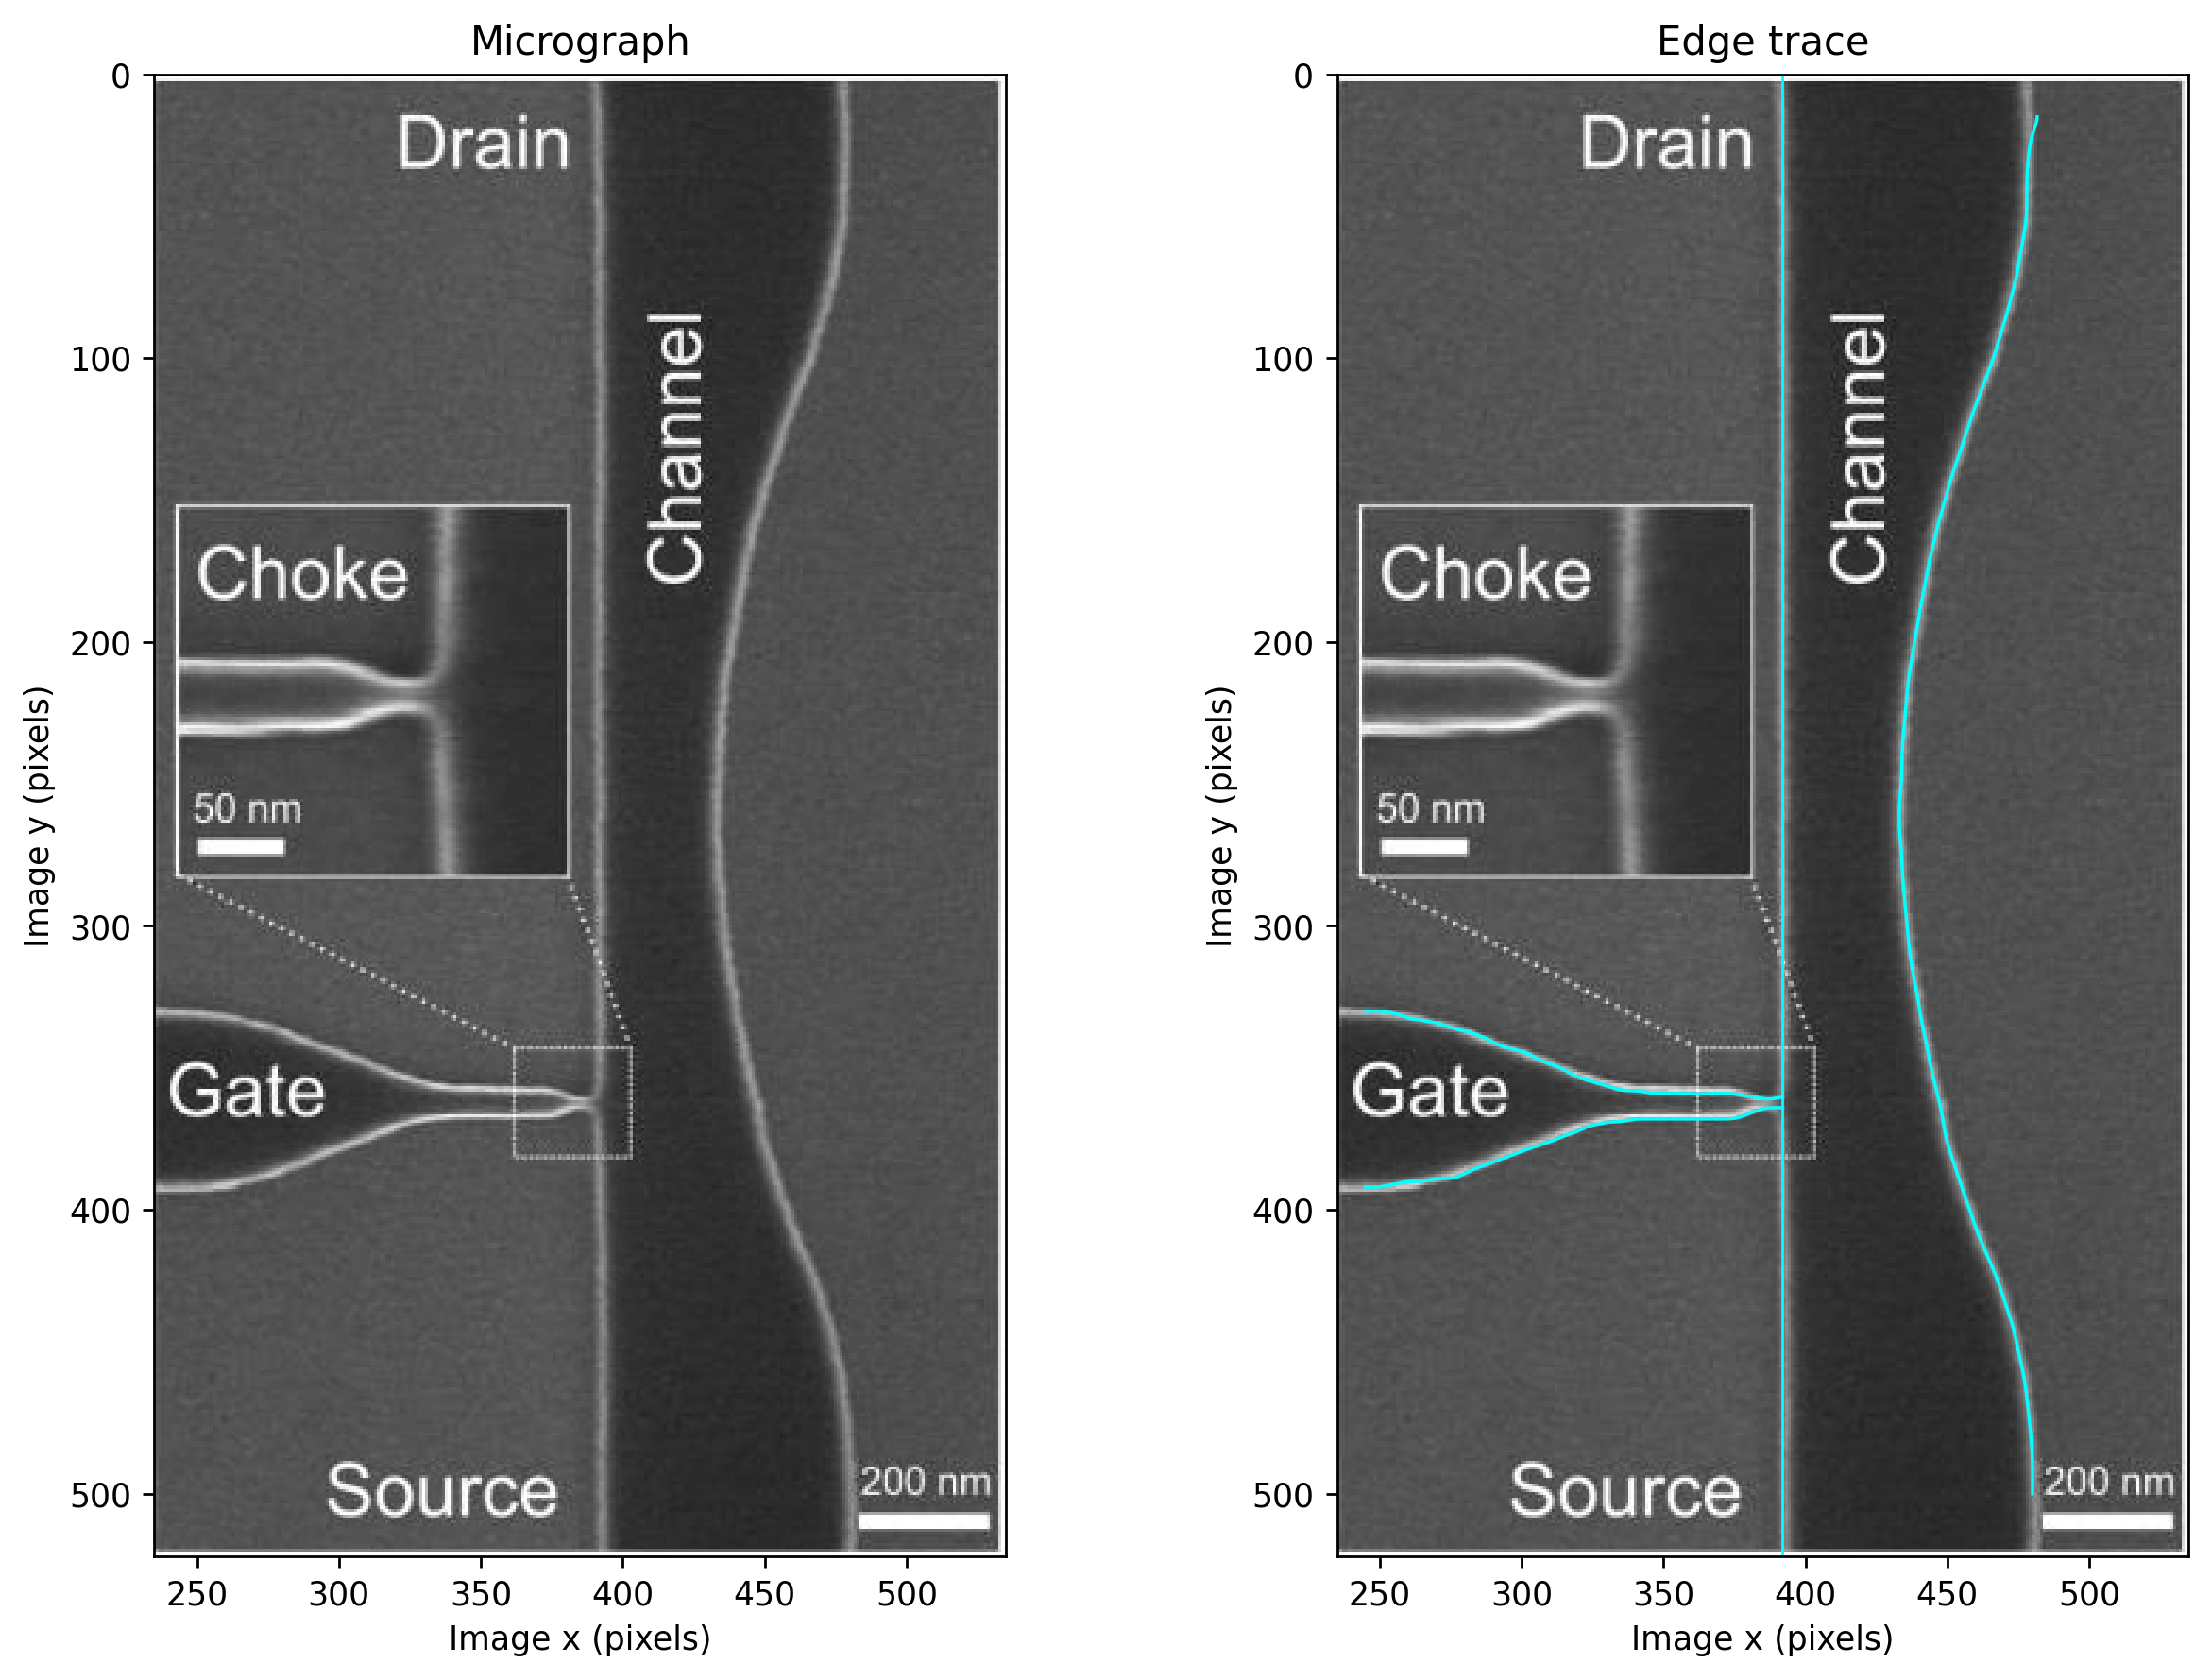

In [3]:
# @title Extract SEM boundaries from the embedded figure
# --- Embedded source image ---
FIGURE_BASE64 = "..."

# --- Scale calibration and SEM edge tracing ---
figure_bytes = base64.b64decode(FIGURE_BASE64)
figure = cv2.cvtColor(
    cv2.imdecode(np.frombuffer(figure_bytes, np.uint8), cv2.IMREAD_COLOR),
    cv2.COLOR_BGR2RGB,
)
gray = cv2.cvtColor(figure, cv2.COLOR_RGB2GRAY).astype(float)
bar = np.all(figure[505:516, 480:533] > 205, axis=2)
bar_x = np.flatnonzero(bar.sum(axis=0) >= 3)
nm_per_px = 200.0 / (bar_x[-1] - bar_x[0] + 1)
blur = gaussian_filter(gray, 0.8)
score = np.exp(-(((blur - 145.0) / 35.0) ** 2))
paths = []
for transpose, scan, states, seed in [
    (False, np.arange(15, 501), np.arange(420, 501), 487),
    (True, np.arange(245, 393), np.arange(322, 369), 331),
    (True, np.arange(245, 393), np.arange(360, 400), 392),
]:
    image = score.T if transpose else score
    local_score = image[np.ix_(scan, states)]
    dp = ((states - seed) / 2.0) ** 2 - local_score[0]
    predecessors = np.zeros(local_score.shape, dtype=int)
    for row in range(1, len(scan)):
        candidate = dp[None, :] + 0.2 * (states[:, None] - states[None, :]) ** 2
        back = candidate.argmin(axis=1)
        dp = candidate[np.arange(len(states)), back] - local_score[row]
        predecessors[row] = back
    selected = np.empty(len(scan), dtype=int)
    selected[-1] = dp.argmin()
    for row in range(len(scan) - 1, 0, -1):
        selected[row - 1] = predecessors[row, selected[row]]
    paths.append(gaussian_filter1d(states[selected].astype(float), 2.0))

right_x, upper_y, lower_y = paths
right_x = gaussian_filter1d(right_x, 4.0)
left_x = 392.0
gate_y = (upper_y[-1] + lower_y[-1]) / 2

raw_choke_nm = (lower_y[-1] - upper_y[-1]) * nm_per_px
print(f"Scale: 200 nm / {len(bar_x)} pixels = {nm_per_px:.3f} nm/pixel")
print(
    f"Traced choke: {raw_choke_nm:.2f} nm; nominal simulation choke: {CHOKE_NM:.2f} nm"
)

fig, axes = plt.subplots(1, 2, figsize=(10, 7), dpi=DPI, layout="constrained")
for ax in axes:
    ax.imshow(figure)
    ax.set(
        xlim=(235, 535),
        ylim=(522, 0),
        xlabel="Image x (pixels)",
        ylabel="Image y (pixels)",
    )
axes[0].set_title("Micrograph")
axes[1].set_title("Edge trace")
axes[1].plot(right_x, np.arange(15, 501), color="cyan", linewidth=1)
axes[1].plot(np.arange(245, 393), upper_y, color="cyan", linewidth=1)
axes[1].plot(np.arange(245, 393), lower_y, color="cyan", linewidth=1)
axes[1].axvline(left_x, color="cyan", linewidth=0.8)
for text in fig.findobj(match=Text):
    text.set_fontfamily("DejaVu Sans")
    text.set_fontweight("normal")
plt.show()


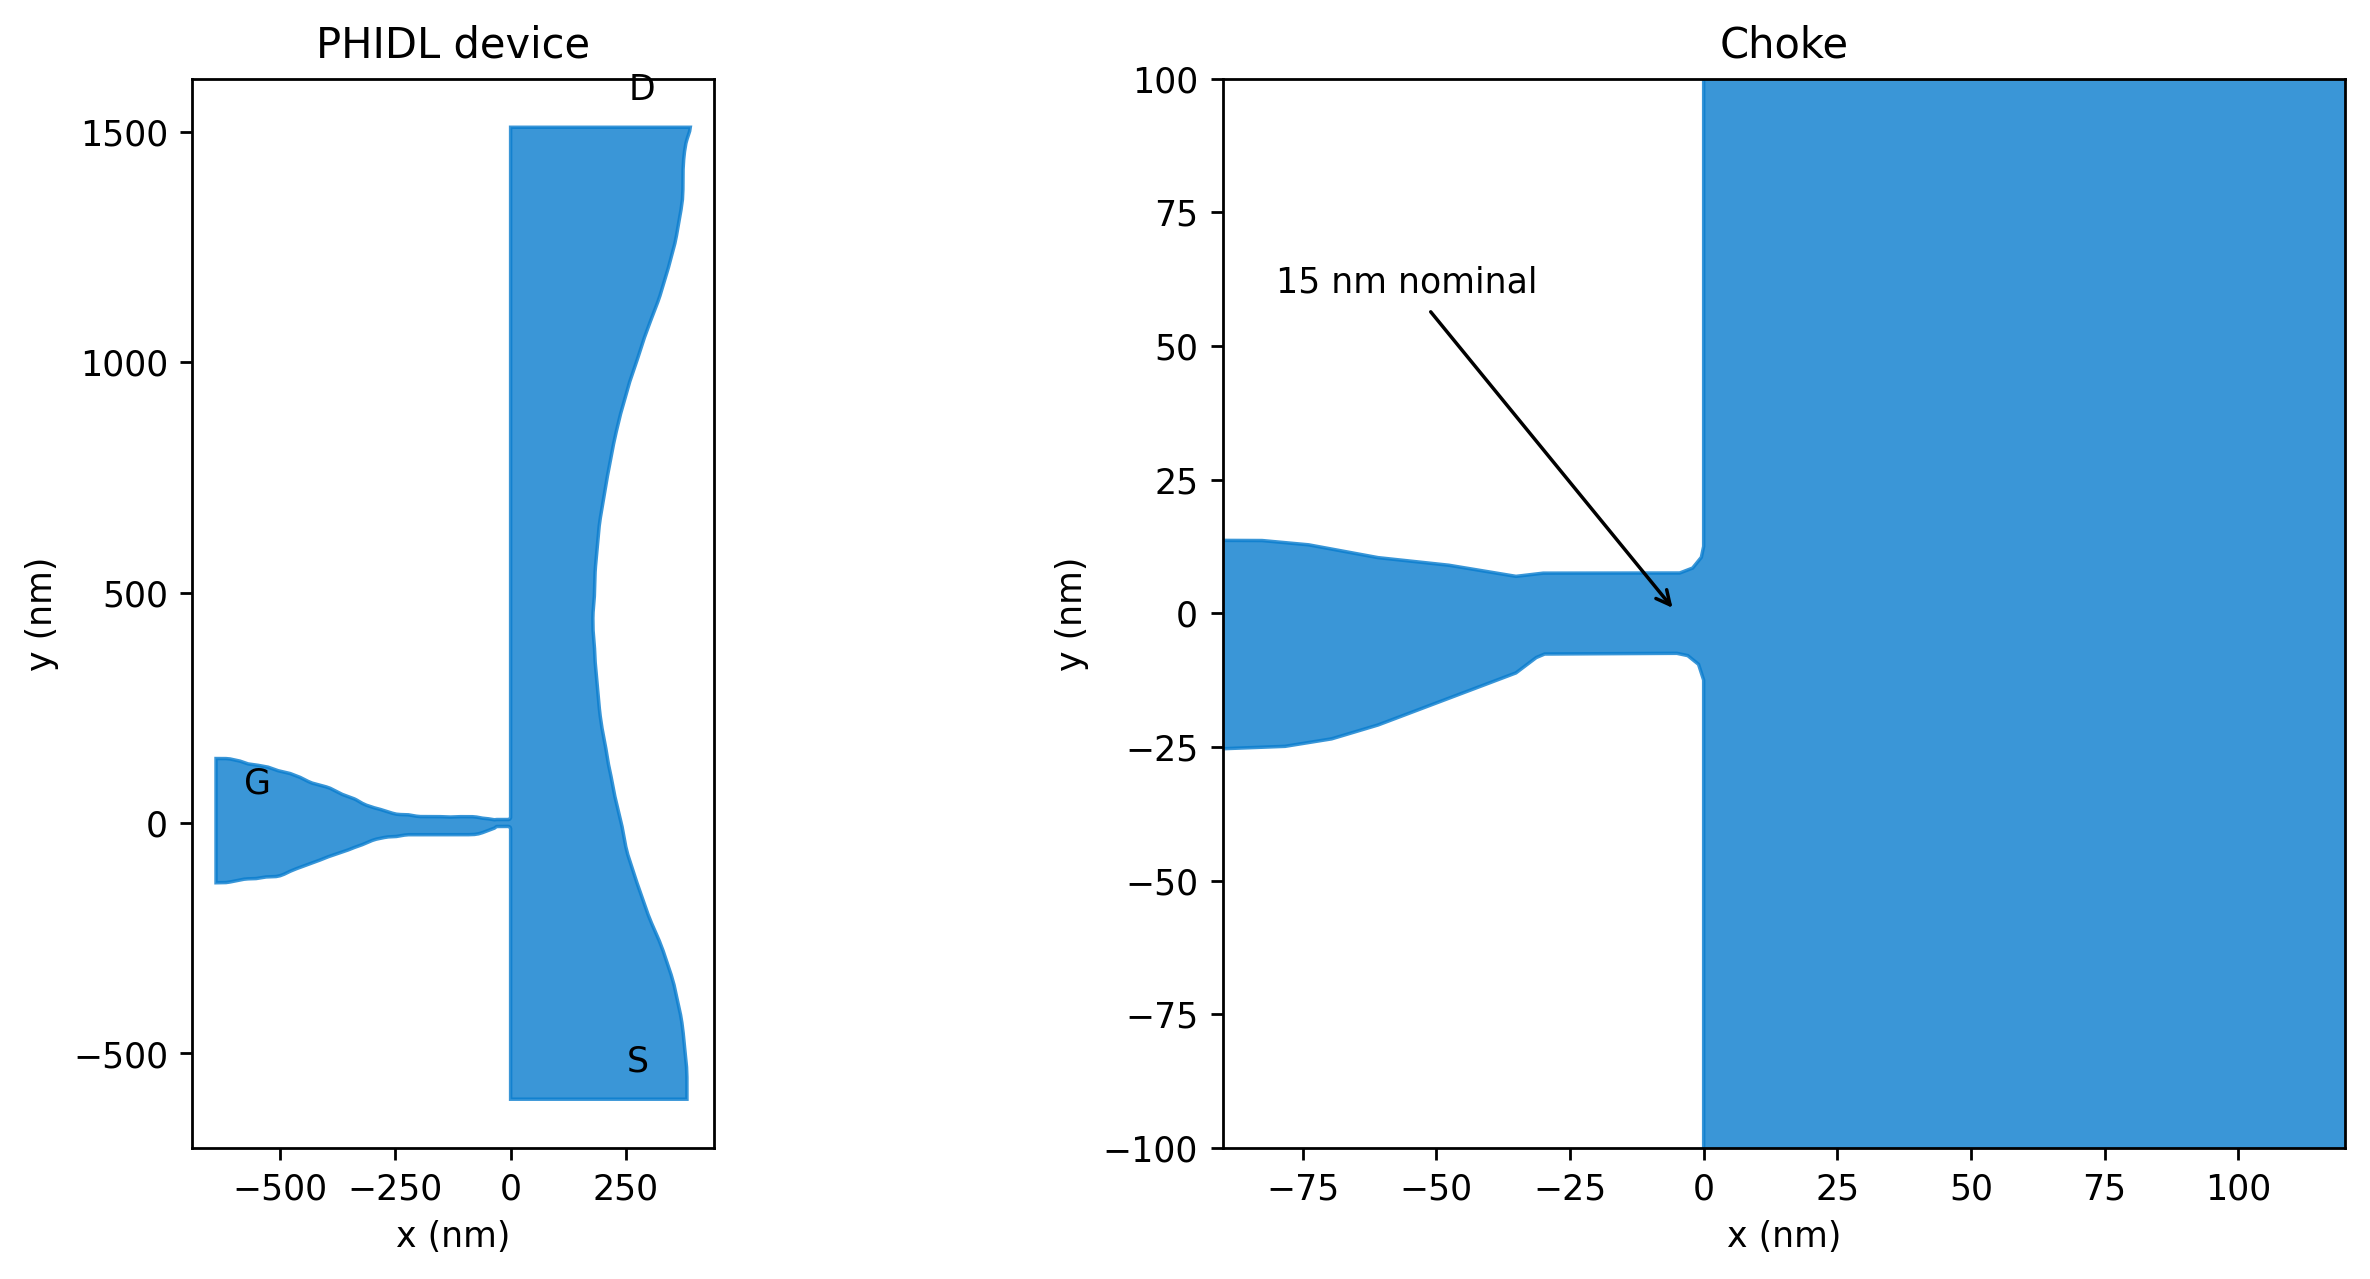

In [4]:
# --- PHIDL reconstruction ---
gx = np.arange(245, 393)
gate_half = (lower_y - upper_y) * nm_per_px / 2
gate_mid = (lower_y + upper_y) / 2
neck_samples = max(3, round(NECK_LENGTH_NM / nm_per_px) + 1)
gate_half[-neck_samples:] = CHOKE_NM / 2
gate_mid[-neck_samples:] = gate_y
x_gate = (gx - left_x) * nm_per_px
x_gate[-1] = max(4 * JUNCTION_RADIUS_NM, 2.0)
y_gate = (gate_y - gate_mid) * nm_per_px
gate_poly = np.vstack(
    (np.c_[x_gate, y_gate + gate_half], np.c_[x_gate[::-1], (y_gate - gate_half)[::-1]])
)
cy_nm = (gate_y - np.arange(15, 501)) * nm_per_px
channel_poly = np.vstack(
    (
        np.c_[np.zeros(2), [cy_nm[0], cy_nm[-1]]],
        np.c_[(right_x[::-1] - left_x) * nm_per_px, cy_nm[::-1]],
    )
)
layout = Device("NTRON_SEM")
layout.add_polygon(channel_poly / 1000, layer=1)
layout.add_polygon(gate_poly / 1000, layer=1)
layout = pg.union(layout, by_layer=True, precision=0.0001)
for polygon in layout.polygons:
    for vertices in polygon.polygons:
        radii = np.where(
            (abs(vertices[:, 0]) < 0.06) & (abs(vertices[:, 1]) < 0.06),
            JUNCTION_RADIUS_NM / 1000,
            0.0,
        )
        polygon.fillet(radius=radii, points_per_2pi=64, max_points=0, precision=0.0001)
assert len(layout.get_polygons()) == 1
outline_nm = layout.get_polygons()[0] * 1000
# Simplify the subpixel traced boundary to 0.25 nm before meshing.
outline_nm = cv2.approxPolyDP(
    outline_nm.astype(np.float32).reshape(-1, 1, 2), 0.25, True
)[:, 0, :].astype(float)

# Rebuild PHIDL from the exact simplified polygon sent to the mesher.
layout = Device("NTRON_SEM_NBN")
layout.add_polygon(outline_nm / 1000.0, layer=(1, 0))
drain_xy = np.array(
    [
        np.mean(outline_nm[np.isclose(outline_nm[:, 1], outline_nm[:, 1].max()), 0]),
        outline_nm[:, 1].max(),
    ]
)
source_xy = np.array(
    [
        np.mean(outline_nm[np.isclose(outline_nm[:, 1], outline_nm[:, 1].min()), 0]),
        outline_nm[:, 1].min(),
    ]
)
gate_xy = np.array(
    [
        outline_nm[:, 0].min(),
        np.mean(outline_nm[np.isclose(outline_nm[:, 0], outline_nm[:, 0].min()), 1]),
    ]
)
for port_name, center_nm, orientation in (
    ("D", drain_xy, 90),
    ("S", source_xy, 270),
    ("G", gate_xy, 180),
):
    if port_name == "G":
        terminal_points = outline_nm[np.isclose(outline_nm[:, 0], center_nm[0]), 1]
    else:
        terminal_points = outline_nm[np.isclose(outline_nm[:, 1], center_nm[1]), 0]
    layout.add_port(
        port_name,
        midpoint=center_nm / 1000,
        width=np.ptp(terminal_points) / 1000,
        orientation=orientation,
    )

fig, axes = plt.subplots(1, 2, figsize=(10, 5), dpi=DPI, layout="constrained")
for ax in axes:
    ax.fill(outline_nm[:, 0], outline_nm[:, 1], color="#087cce", alpha=0.8)
    ax.set_aspect("equal")
    ax.set(xlabel="x (nm)", ylabel="y (nm)")
axes[0].set_title("PHIDL device")
for name, center in (("D", drain_xy), ("S", source_xy), ("G", gate_xy)):
    axes[0].annotate(name, center, xytext=(8, 8), textcoords="offset points")
axes[1].set(xlim=(-90, 120), ylim=(-100, 100), title="Choke")
axes[1].annotate(
    f"{CHOKE_NM:g} nm nominal",
    (-5, 0),
    xytext=(-80, 60),
    arrowprops={"arrowstyle": "->"},
)
for text in fig.findobj(match=Text):
    text.set_fontfamily("DejaVu Sans")
    text.set_fontweight("normal")
plt.show()


## Finite element mesh and cold-current check

Triangle refines the choke to a target triangle area of 8 nm² within 50 nm of the junction, then increases the area to 60 nm² within 130 nm and 200 nm² farther away. `MESH_AREA_SCALE` scales these targets. First-order triangular elements represent potential and temperature, while elementwise sheet current follows the potential gradient and its inductive history.

Contact-node elimination enforces three equipotential terminals, and the grounded source removes the potential gauge. A unit drain-current solution supplies both the cold current-crowding limit and the geometry-dependent kinetic inductance. The two inline form kernels appear in every time step; no helper functions are defined.

MESH 3473 6546 contacts 20 19 17
Ic_est 109.08277540876301 Ib 98.17449786788671 Ls 31.17588132077205
Device kinetic inductance for drain current: 0.261 nH
Series inductance: 1.000 nH; load: 50 ohms
Approximate baseline electrical recovery: 25.23 ps


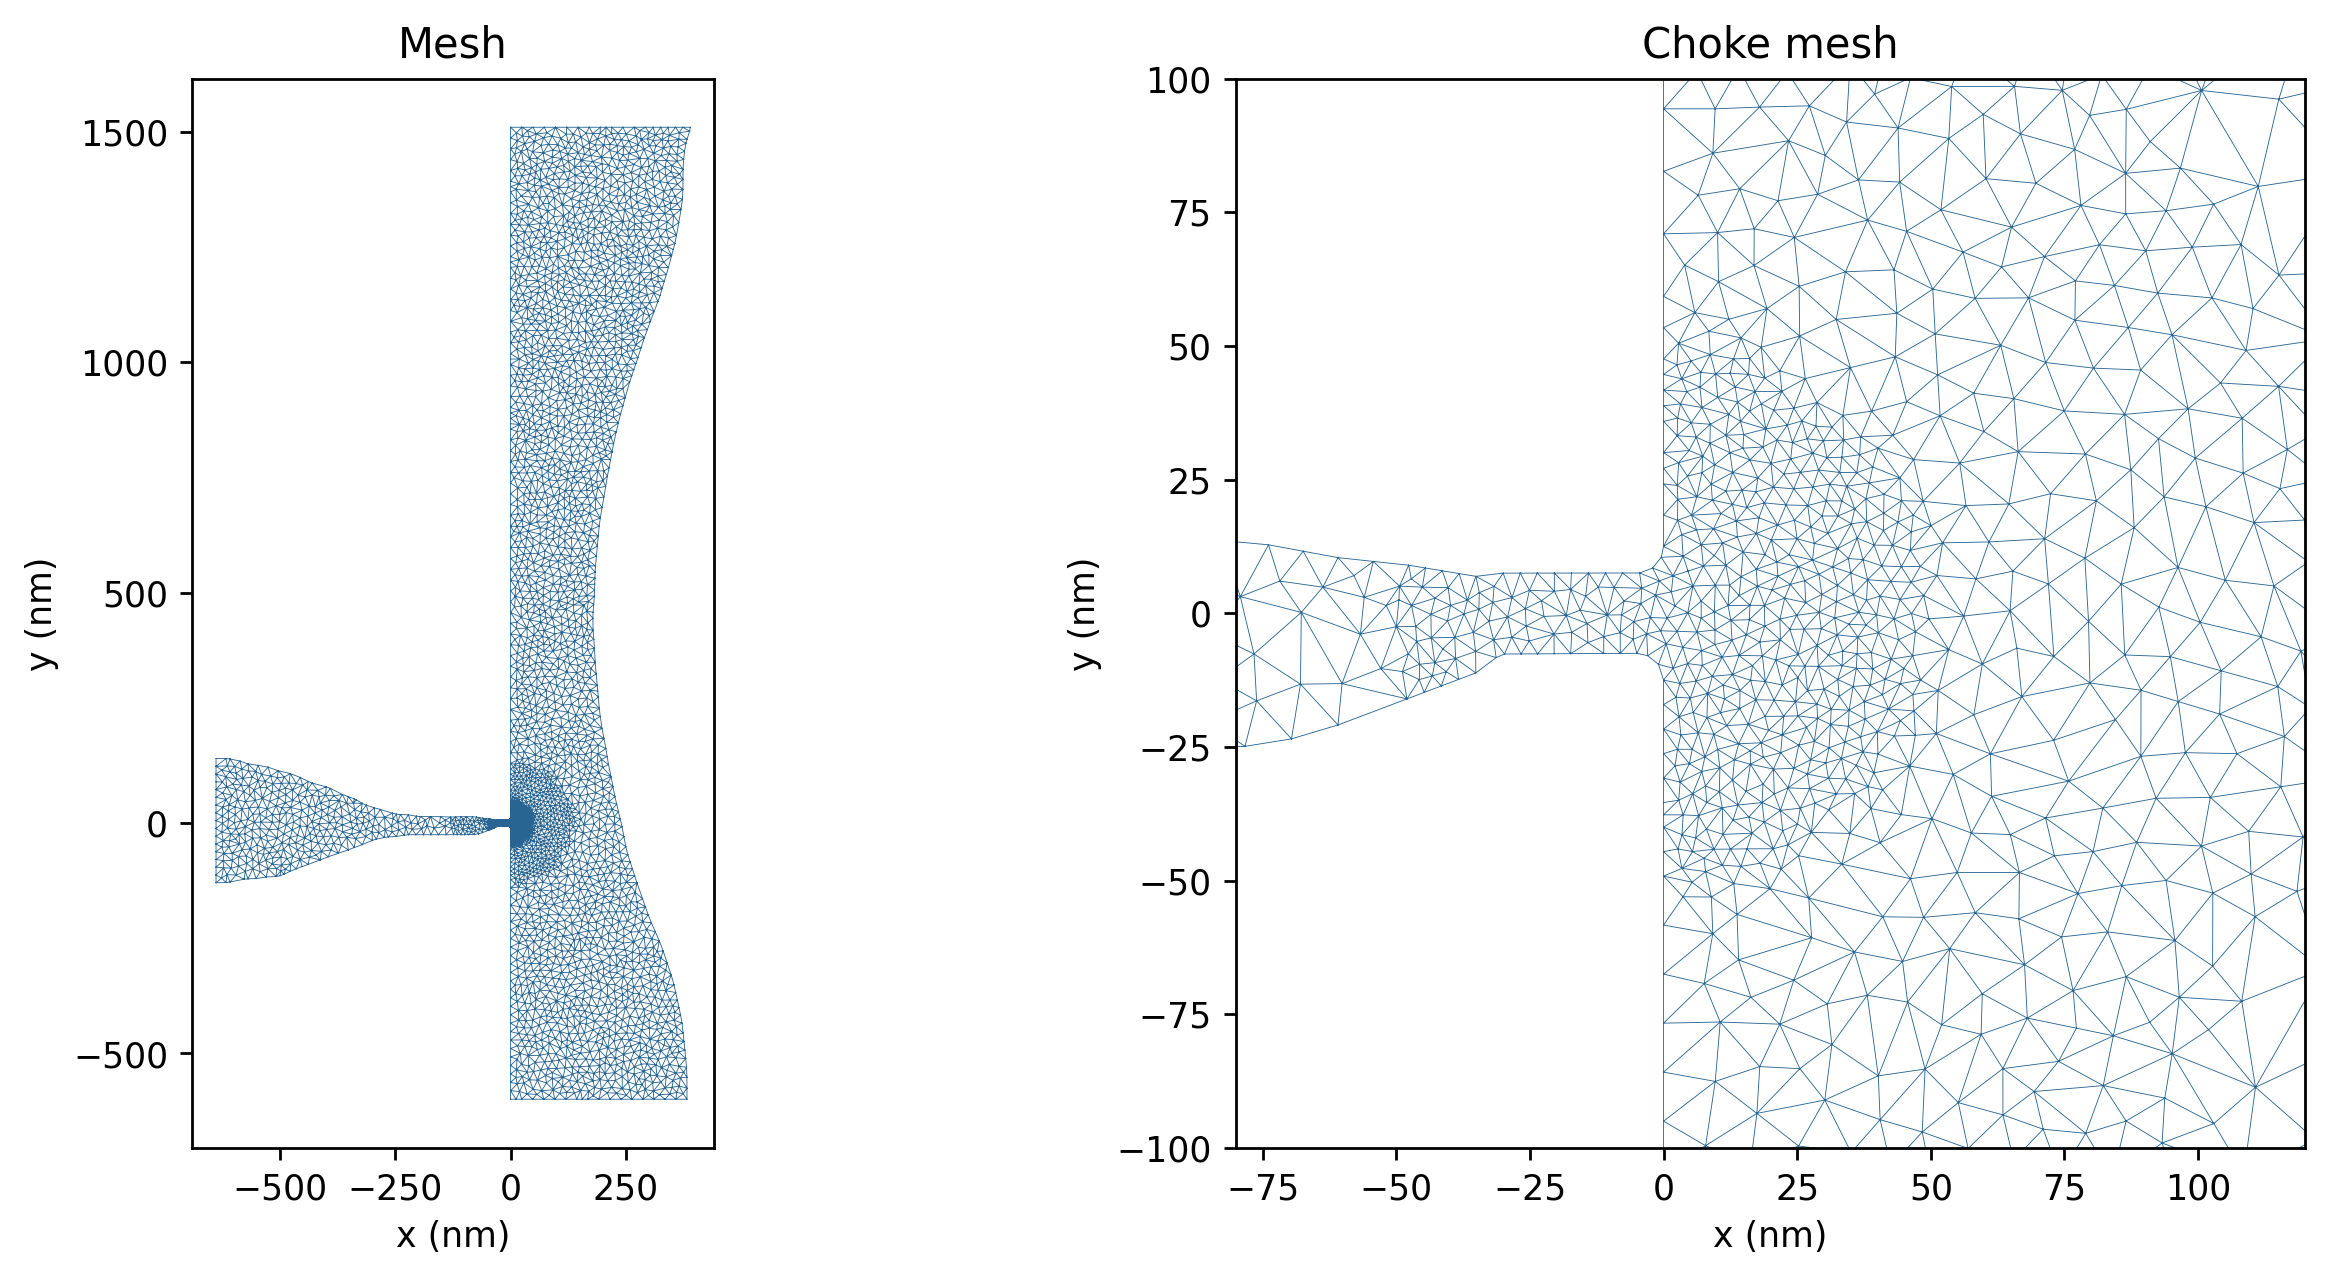

In [5]:
segments = np.c_[np.arange(len(outline_nm)), np.roll(np.arange(len(outline_nm)), -1)]
tri = tr.triangulate(
    {"vertices": outline_nm, "segments": segments}, f"pq28a{200 * MESH_AREA_SCALE:.8f}"
)
points = tri["vertices"]
cells = tri["triangles"]
for _ in range(2):
    center = points[cells].mean(axis=1)
    edge_a = points[cells[:, 1]] - points[cells[:, 0]]
    edge_b = points[cells[:, 2]] - points[cells[:, 0]]
    area = np.abs(edge_a[:, 0] * edge_b[:, 1] - edge_a[:, 1] * edge_b[:, 0]) / 2
    radius = np.linalg.norm(center, axis=1)
    target = np.select(
        [radius < 50, radius < 130, radius < 250], [8.0, 60.0, 200.0], default=200.0
    )
    tri["triangle_max_area"] = (target * MESH_AREA_SCALE)[:, None]
    tri = tr.triangulate(tri, "rpq28a")
    points, cells = tri["vertices"], tri["triangles"]
mesh = MeshTri(points.T * 1e-9, cells.T)
basis = Basis(mesh, ElementTriP1())
n = basis.N
area = basis.dx.sum(axis=1)
lump = np.asarray(asm(mass, basis).sum(axis=1)).ravel()
boundary = mesh.boundary_nodes()
drain = boundary[np.isclose(mesh.p[1, boundary], mesh.p[1].max(), atol=1e-12)]
source = boundary[np.isclose(mesh.p[1, boundary], mesh.p[1].min(), atol=1e-12)]
gate = boundary[np.isclose(mesh.p[0, boundary], mesh.p[0].min(), atol=1e-12)]
contacts = np.unique(np.r_[source, drain, gate])
inside = np.setdiff1d(np.arange(n), contacts)
node_map = np.full(n, -1, dtype=int)
node_map[inside] = np.arange(len(inside))
drain_dof, gate_dof = len(inside), len(inside) + 1
node_map[drain], node_map[gate] = drain_dof, gate_dof
valid = node_map >= 0
P = sparse.csr_matrix(
    (np.ones(valid.sum()), (np.flatnonzero(valid), node_map[valid])),
    shape=(n, len(inside) + 2),
)
thermal_free = np.setdiff1d(np.arange(2 * n), np.r_[contacts, contacts + n])
thermal_fixed = np.r_[contacts, contacts + n]
diffusion = BilinearForm(lambda u, v, w: w.c * dot(grad(u), grad(v)))
flux_rhs = LinearForm(lambda v, w: dot(w.flux, grad(v)))
base_matrix = (P.T @ asm(laplace, basis) @ P).tocsc()
rhs = np.zeros(P.shape[1])
rhs[drain_dof] = 1.0
unit_phi = P @ spsolve(base_matrix, rhs)
unit_K = -basis.interpolate(unit_phi).grad[:, :, 0]
Ic_est = Jc_bath * d / np.linalg.norm(unit_K, axis=0).max()
Ib = BIAS_FRACTION * Ic_est
print(
    "MESH",
    n,
    mesh.nelements,
    "contacts",
    len(drain),
    len(source),
    len(gate),
    flush=True,
)
print("Ic_est", Ic_est * 1e6, "Ib", Ib * 1e6, "Ls", Ls0 * 1e12, flush=True)


assert np.all(area > 0) and len(gate) > 1 and len(drain) > 1 and len(source) > 1
assert sparse.csgraph.connected_components(asm(laplace, basis), directed=False)[0] == 1
Ldevice0 = Ls0 * np.sum(np.sum(unit_K**2, axis=0) * area)
print(f"Device kinetic inductance for drain current: {Ldevice0 * 1e9:.3f} nH")
print(f"Series inductance: {Lext * 1e9:.3f} nH; load: {RL:g} ohms")
print(
    f"Approximate baseline electrical recovery: {(Ldevice0 + Lext) / RL * 1e12:.2f} ps"
)

tri_plot = mtri.Triangulation(mesh.p[0] * 1e9, mesh.p[1] * 1e9, mesh.t.T)
fig, axes = plt.subplots(1, 2, figsize=(10, 5), dpi=DPI, layout="constrained")
for ax in axes:
    ax.triplot(tri_plot, color="#286593", linewidth=0.25)
    ax.set_aspect("equal")
    ax.set(xlabel="x (nm)", ylabel="y (nm)")
axes[0].set_title("Mesh")
axes[1].set(xlim=(-80, 120), ylim=(-100, 100), title="Choke mesh")
for text in fig.findobj(match=Text):
    text.set_fontfamily("DejaVu Sans")
    text.set_fontweight("normal")
plt.show()


In [6]:
# --- Independent cold-mesh refinement check ---
mesh_check = []
for refinement in [0, 1] if VERIFY_MESH else [0]:
    check_mesh = mesh if refinement == 0 else mesh.refined()
    check_basis = Basis(check_mesh, ElementTriP1())
    check_boundary = check_mesh.boundary_nodes()
    check_drain = check_boundary[
        np.isclose(check_mesh.p[1, check_boundary], check_mesh.p[1].max(), atol=1e-12)
    ]
    check_source = check_boundary[
        np.isclose(check_mesh.p[1, check_boundary], check_mesh.p[1].min(), atol=1e-12)
    ]
    check_gate = check_boundary[
        np.isclose(check_mesh.p[0, check_boundary], check_mesh.p[0].min(), atol=1e-12)
    ]
    check_inside = np.setdiff1d(
        np.arange(check_basis.N), np.r_[check_drain, check_source, check_gate]
    )
    check_map = np.full(check_basis.N, -1, dtype=int)
    check_map[check_inside] = np.arange(len(check_inside))
    check_map[check_drain] = len(check_inside)
    check_map[check_gate] = len(check_inside) + 1
    check_valid = check_map >= 0
    check_P = sparse.csr_matrix(
        (
            np.ones(check_valid.sum()),
            (np.flatnonzero(check_valid), check_map[check_valid]),
        ),
        shape=(check_basis.N, len(check_inside) + 2),
    )
    check_rhs = np.zeros(check_P.shape[1])
    check_rhs[len(check_inside)] = 1.0
    check_phi = check_P @ spsolve(
        (check_P.T @ asm(laplace, check_basis) @ check_P).tocsc(), check_rhs
    )
    check_K = -check_basis.interpolate(check_phi).grad[:, :, 0]
    check_Ic = Jc_bath * d / np.linalg.norm(check_K, axis=0).max()
    check_L = Ls0 * np.sum(np.sum(check_K**2, axis=0) * check_basis.dx.sum(axis=1))
    mesh_check.append((check_basis.N, check_Ic, check_L))
    print(
        f"Nodes: {check_basis.N:6d}; cold limit: {check_Ic * 1e6:8.3f} uA; inductance: {check_L * 1e9:.6f} nH"
    )
if VERIFY_MESH:
    print(
        f"Cold-limit relative change: {abs(mesh_check[-1][1] / mesh_check[0][1] - 1):.2%}"
    )
    print(
        f"Inductance relative change: {abs(mesh_check[-1][2] / mesh_check[0][2] - 1):.2%}"
    )


Nodes:   3473; cold limit:  109.083 uA; inductance: 0.261478 nH
Nodes:  13491; cold limit:  108.331 uA; inductance: 0.261490 nH
Cold-limit relative change: 0.69%
Inductance relative change: 0.00%


## Transient solution

Backward Euler updates the distributed inductive current and the external circuit. Each step evaluates resistivity from the previous temperature and current, solves charge continuity, and then updates both temperatures through one coupled sparse thermal system. The electron-phonon exchange terms enter with opposite signs, which ensures equal energy transfer between the two systems in the discretized equations.

The channel bias begins at 90% of the cold current-crowding estimate, and a 25 microampere gate pulse spans 50–100 ps. A smooth 220–420 ps bias interruption then tests reset; set `ENABLE_BIAS_RESET=False` to inspect sustained latching. A higher-inductance run holds resistance, critical current, geometry, and thermal coefficients fixed, thereby separating the inductive response from a complete material substitution.

Electrical energy checks include the nonnegative numerical damping introduced by backward Euler. A separate thermal balance uses the same lagged heat capacities as the solved equations, so it checks algebraic conservation within this semi-implicit scheme. The shorter-step run quantifies sensitivity to the explicit resistive-fraction update; the printed differences measure numerical sensitivity, not agreement with an experiment.

Bias interruption and reapplication also drive inductive voltage pulses in the no-gate control. Compare gate responses before the reset window, where that control has essentially zero output; the later control pulses describe energy moving between the inductor and the load.


In [7]:
# --- Scenarios ---
cases = [
    ("No gate", 0.0, 1.0, DT_PS, STOP_PS),
    ("Gate pulse", GATE_PEAK_UA * 1e-6, 1.0, DT_PS, STOP_PS),
    ("Fourfold inductance", GATE_PEAK_UA * 1e-6, INDUCTANCE_MULTIPLIER, DT_PS, STOP_PS),
]
if VERIFY_TIME_STEP:
    cases.append(
        (
            "Half time step",
            GATE_PEAK_UA * 1e-6,
            1.0,
            DT_PS / 2,
            min(VERIFY_STOP_PS, STOP_PS),
        )
    )

# --- Coupled current and temperature solve ---
results = []
start = time.perf_counter()
for name, gate_peak, multiplier, dt_ps, run_stop_ps in cases:
    dt = dt_ps * 1e-12
    times = np.arange(1, round(run_stop_ps / dt_ps) + 1) * dt
    field_stride = max(1, round(FIELD_INTERVAL_PS / dt_ps))
    max_electrical_residual = 0.0
    max_thermal_residual = 0.0
    max_current_residual = 0.0
    max_power = 1e-30
    energy_old = (
        0.5 * Ls0 * multiplier * np.sum(np.sum((unit_K * Ib) ** 2, axis=0) * area)
        + 0.5 * Lext * Ib**2
    )
    Te = np.full(n, Tb)
    Tp = Te.copy()
    Kprev = unit_K * Ib
    Ich = Ib
    Ls = Ls0 * multiplier
    data = []
    snapshots = []
    for step, now in enumerate(times):
        old_Ich = Ich
        old_Te, old_Tp = Te.copy(), Tp.copy()
        bias_current = Ib
        if ENABLE_BIAS_RESET:
            bias_current *= 1 - 0.5 * (
                np.tanh((now - RESET_START_PS * 1e-12) / (PULSE_EDGE_PS * 1e-12))
                - np.tanh((now - RESET_END_PS * 1e-12) / (PULSE_EDGE_PS * 1e-12))
            )
        gate_current = (
            gate_peak
            * 0.5
            * (
                np.tanh((now - GATE_START_PS * 1e-12) / (PULSE_EDGE_PS * 1e-12))
                - np.tanh((now - GATE_END_PS * 1e-12) / (PULSE_EDGE_PS * 1e-12))
            )
        )
        te = Te[mesh.t].mean(axis=0)
        tp = Tp[mesh.t].mean(axis=0)
        reduced = np.minimum(te / Tc, 1.0)
        jc = (
            Jc_bath
            * (np.maximum(1 - reduced**2, 0) ** 1.5 * np.sqrt(1 + reduced**2))
            / ((1 - (Tb / Tc) ** 2) ** 1.5 * np.sqrt(1 + (Tb / Tc) ** 2))
        )
        fT = expit((te - Tc) / TEMPERATURE_WIDTH_K)
        fI = expit(
            (np.linalg.norm(Kprev, axis=0) - jc * d)
            / (CURRENT_WIDTH_FRACTION * Jc_bath * d)
        )
        fraction = 1 - (1 - fT) * (1 - fI)
        resistance = Rs * fraction
        B = 1 / (resistance + Ls / dt)
        A = B * Ls / dt
        matrix = (P.T @ asm(diffusion, basis, c=B[:, None]) @ P).tocsc()
        q = asm(
            flux_rhs,
            basis,
            flux=(Kprev * A)[..., None] * np.ones((1, 1, basis.dx.shape[1])),
        )
        rhs = np.asarray(P.T @ q).ravel()
        conductance = 1 / (RL + Lext / dt)
        matrix[drain_dof, drain_dof] += conductance
        rhs[drain_dof] += (RL * bias_current + Lext / dt * Ich) * conductance
        rhs[gate_dof] += gate_current
        phi = P @ spsolve(matrix, rhs)
        K = Kprev * A - B * basis.interpolate(phi).grad[:, :, 0]
        Ich = (RL * bias_current + Lext / dt * Ich - phi[drain[0]]) * conductance
        voltage = RL * (bias_current - Ich)
        qcell = resistance * np.sum(K * K, axis=0)
        qload = np.bincount(
            mesh.t.ravel(), weights=np.tile(qcell * area / 3, 3), minlength=n
        )
        Ce = gamma * Te
        Cp = alpha * Tp**3
        mix = (Te + Tp) / 2
        Gep = gamma * Tc / (EP_TIME_AT_TC_PS * 1e-12) * (mix / Tc) ** 4
        ge = Gep * d * lump
        esc = Cp / (ESCAPE_TIME_PS * 1e-12) * d * lump
        me = Ce * d * lump / dt
        mp = Cp * d * lump / dt
        ke = lorenz * te / (Rs * d)
        kp = alpha * tp**3 * PHONON_DIFFUSIVITY_M2_S
        Ke = asm(diffusion, basis, c=(ke * d)[:, None])
        Kp = asm(diffusion, basis, c=(kp * d)[:, None])
        coupling = sparse.diags(ge)
        H = sparse.bmat(
            [
                [Ke + sparse.diags(me + ge), -coupling],
                [-coupling, Kp + sparse.diags(mp + ge + esc)],
            ],
            format="csc",
        )
        hrhs = np.r_[me * Te + qload, mp * Tp + esc * Tb]
        temp = np.full(2 * n, Tb)
        temp[thermal_free] = spsolve(
            H[thermal_free][:, thermal_free],
            hrhs[thermal_free]
            - H[thermal_free][:, thermal_fixed] @ temp[thermal_fixed],
        )
        Te, Tp = temp[:n], temp[n:]
        assert np.isfinite(temp).all() and temp.min() > 0
        # Electrical power balance, including backward-Euler damping.
        joule_power = np.sum(qcell * area)
        energy_new = (
            0.5 * Ls * np.sum(np.sum(K * K, axis=0) * area) + 0.5 * Lext * Ich**2
        )
        be_damping = (
            0.5 * Ls * np.sum(np.sum((K - Kprev) ** 2, axis=0) * area)
            + 0.5 * Lext * (Ich - old_Ich) ** 2
        ) / dt
        input_power = bias_current * voltage + gate_current * phi[gate[0]]
        load_power = voltage**2 / RL
        electrical_error = (
            input_power
            - load_power
            - joule_power
            - (energy_new - energy_old) / dt
            - be_damping
        )
        max_electrical_residual = max(max_electrical_residual, abs(electrical_error))
        max_power = max(max_power, abs(input_power), joule_power, load_power)
        energy_old = energy_new

        reaction = H @ temp - hrhs
        contact_loss = -reaction[thermal_fixed].sum()
        escape_power = np.sum(esc * (Tp - Tb))
        linear_heat_rate = np.sum(me * (Te - old_Te) + mp * (Tp - old_Tp))
        thermal_error = joule_power - contact_loss - escape_power - linear_heat_rate
        max_thermal_residual = max(max_thermal_residual, abs(thermal_error))

        continuity = (
            P.T
            @ asm(
                flux_rhs, basis, flux=K[..., None] * np.ones((1, 1, basis.dx.shape[1]))
            )
        ).ravel()
        continuity[drain_dof] += Ich
        continuity[gate_dof] += gate_current
        max_current_residual = max(max_current_residual, np.abs(continuity).max())

        data.append(
            [
                now,
                gate_current,
                Ich,
                voltage,
                Te.max(),
                Tp.max(),
                joule_power,
                fraction.max(),
                bias_current,
            ]
        )
        if (step + 1) % max(1, len(times) // 4) == 0:
            print(f"{name}: {(step + 1) / len(times):.0%}", flush=True)
        if step % field_stride == 0:
            snapshots.append((now, Te.copy(), fraction.copy(), K.copy()))
        Kprev = K
    results.append(
        {
            "name": name,
            "data": np.array(data),
            "snapshots": snapshots,
            "electrical_residual": max_electrical_residual / max_power,
            "thermal_residual": max_thermal_residual / max_power,
            "current_residual": max_current_residual / Ib,
            "dt_ps": dt_ps,
        }
    )
    a = np.array(data)
    print(
        f"{name}: peak output {a[:,3].max()*1e3:.3f} mV; peak electron temperature {a[:,4].max():.2f} K; elapsed {time.perf_counter()-start:.1f} s",
        flush=True,
    )

No gate: 25%
No gate: 50%
No gate: 75%
No gate: 100%
No gate: peak output 3.451 mV; peak electron temperature 4.20 K; elapsed 151.7 s
Gate pulse: 25%
Gate pulse: 50%
Gate pulse: 75%
Gate pulse: 100%
Gate pulse: peak output 4.055 mV; peak electron temperature 39.78 K; elapsed 287.1 s
Fourfold inductance: 25%
Fourfold inductance: 50%
Fourfold inductance: 75%
Fourfold inductance: 100%
Fourfold inductance: peak output 4.236 mV; peak electron temperature 39.81 K; elapsed 420.1 s
Half time step: 25%
Half time step: 50%
Half time step: 75%
Half time step: 100%
Half time step: peak output 4.159 mV; peak electron temperature 39.78 K; elapsed 500.2 s


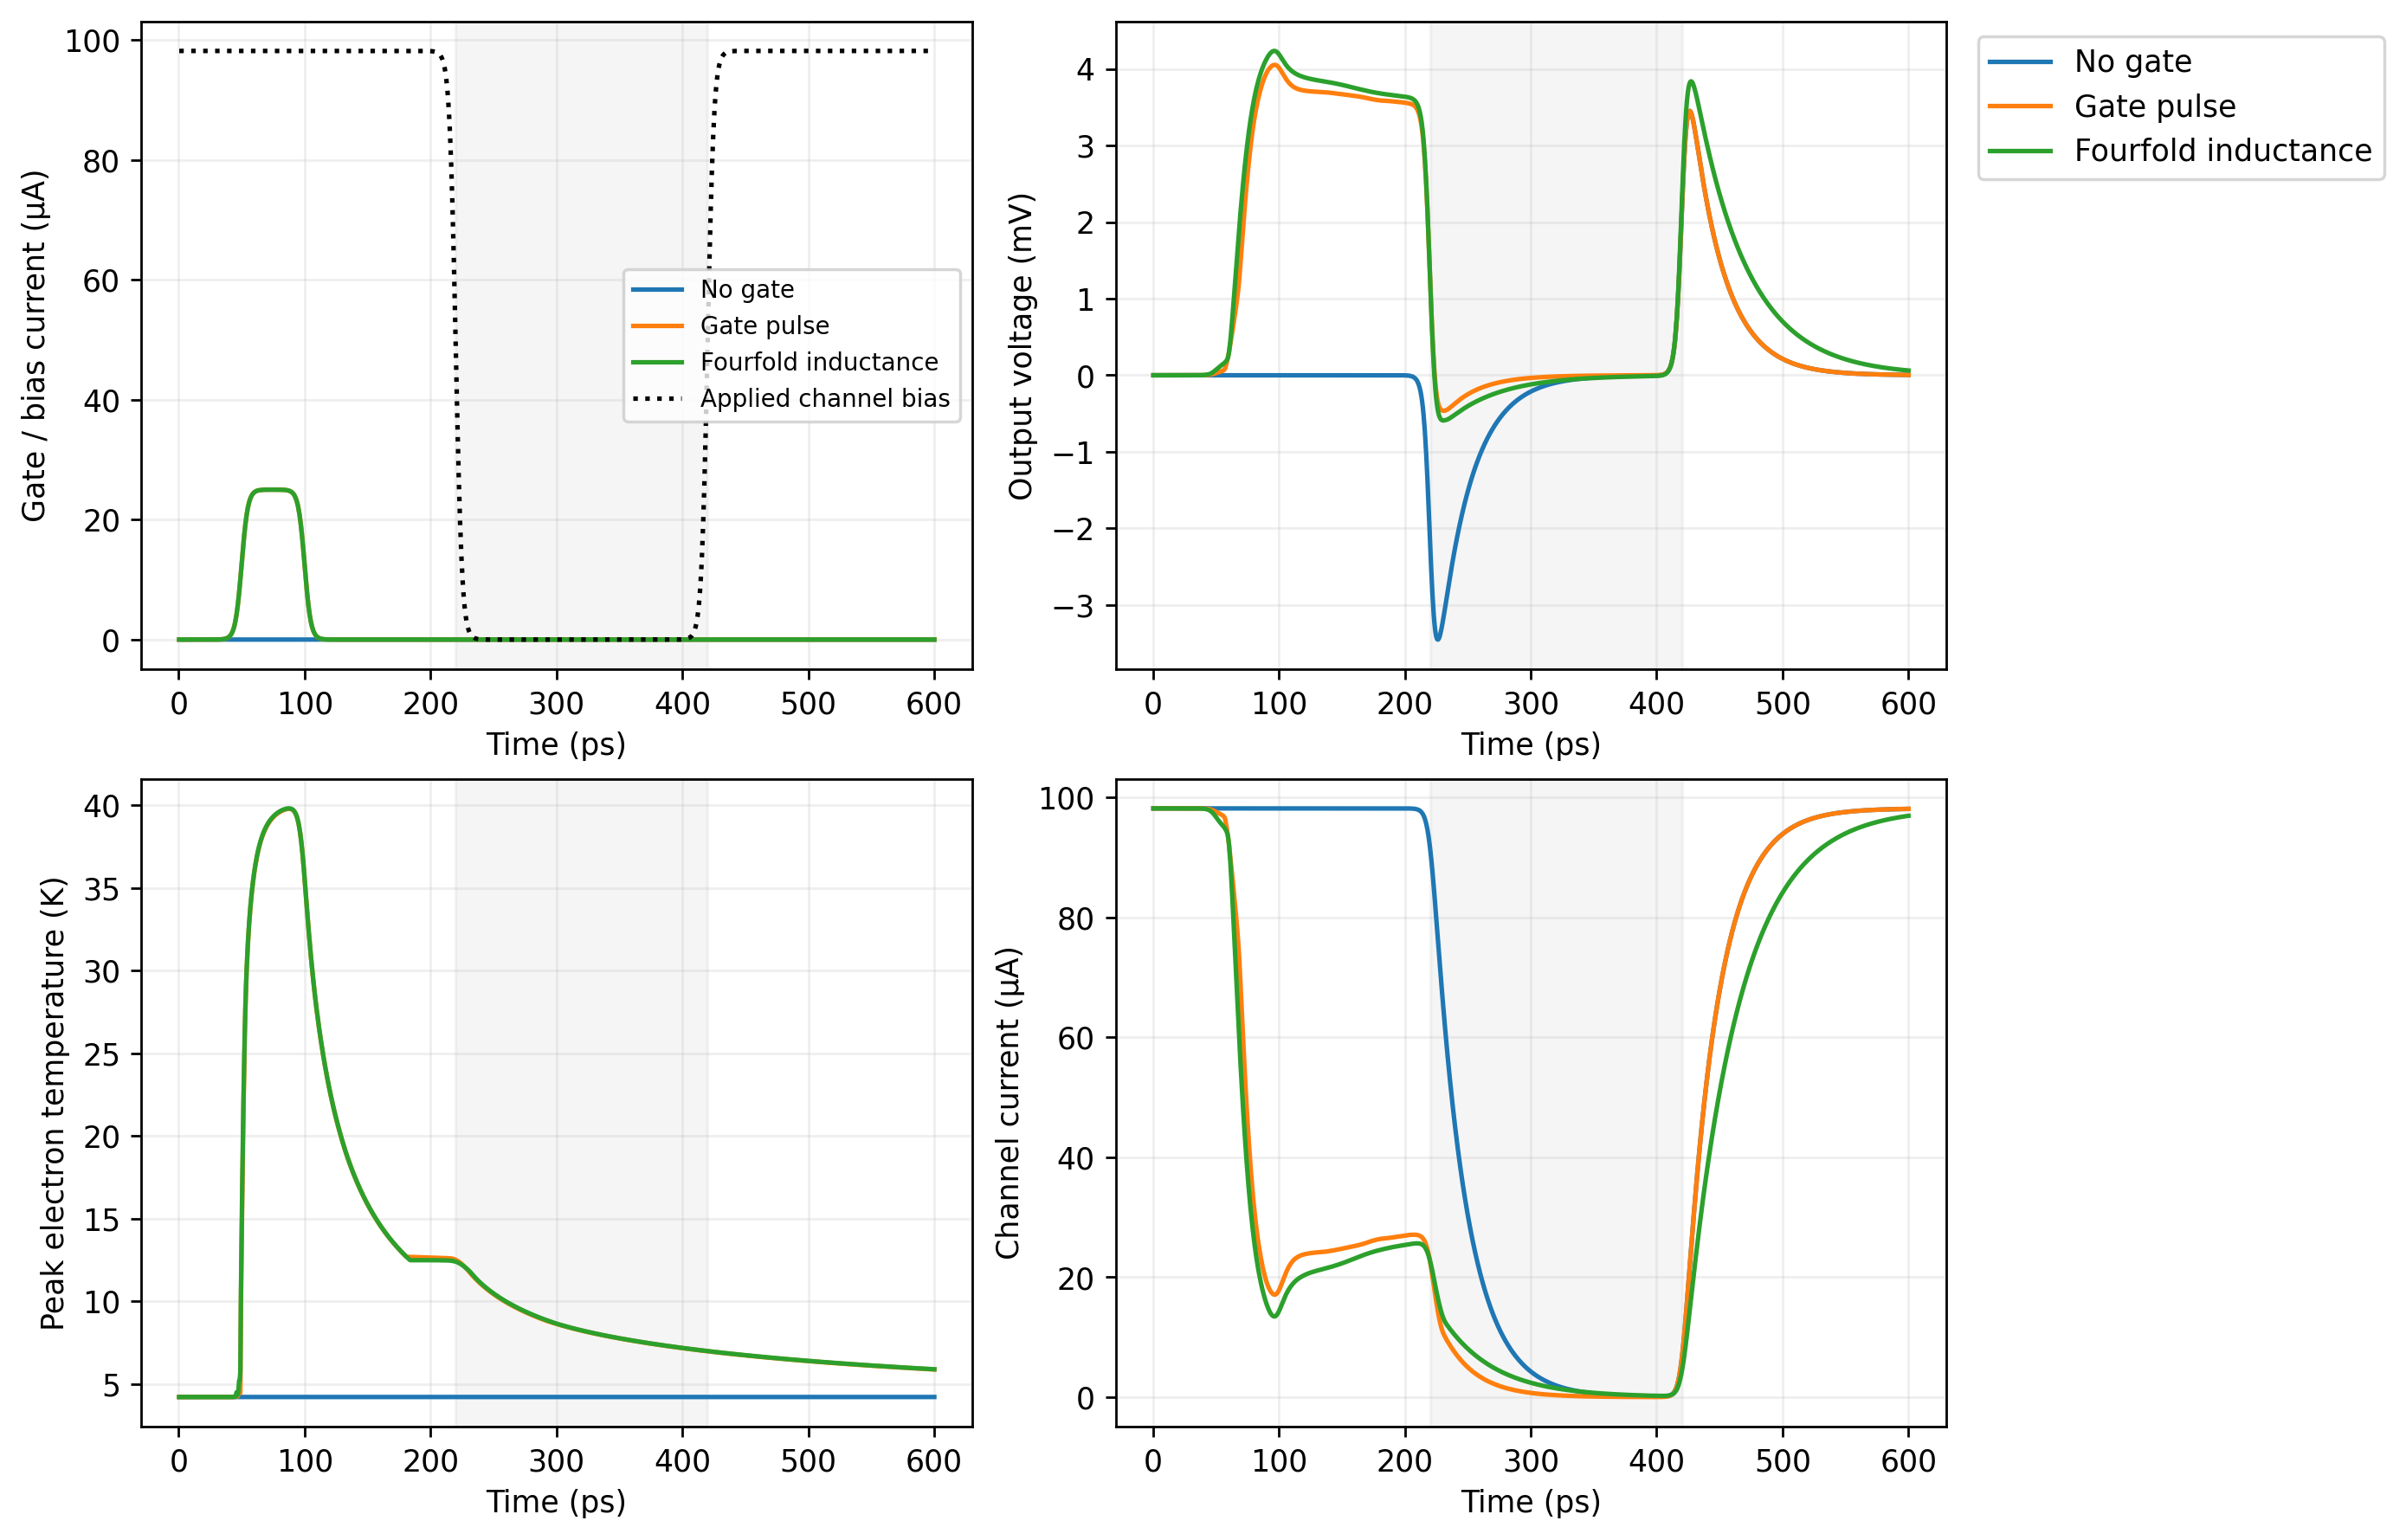

In [8]:
# --- Waveforms ---
fig, axes = plt.subplots(2, 2, figsize=(11, 7), dpi=DPI, layout="constrained")
for result in results[:3]:
    data = result["data"]
    label = result["name"]
    axes[0, 0].plot(data[:, 0] * 1e12, data[:, 1] * 1e6, label=label)
    axes[0, 1].plot(data[:, 0] * 1e12, data[:, 3] * 1e3, label=label)
    axes[1, 0].plot(data[:, 0] * 1e12, data[:, 4], label=label)
    axes[1, 1].plot(data[:, 0] * 1e12, data[:, 2] * 1e6, label=label)
axes[0, 0].plot(
    results[0]["data"][:, 0] * 1e12,
    results[0]["data"][:, 8] * 1e6,
    color="black",
    linestyle=":",
    label="Applied channel bias",
)
for ax, ylabel in zip(
    axes.ravel(),
    (
        "Gate / bias current (µA)",
        "Output voltage (mV)",
        "Peak electron temperature (K)",
        "Channel current (µA)",
    ),
):
    ax.set(xlabel="Time (ps)", ylabel=ylabel)
    ax.grid(alpha=0.2)
    if ENABLE_BIAS_RESET:
        ax.axvspan(RESET_START_PS, RESET_END_PS, color="gray", alpha=0.08)
axes[0, 1].legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
axes[0, 0].legend(fontsize=8)
for text in fig.findobj(match=Text):
    text.set_fontfamily("DejaVu Sans")
    text.set_fontweight("normal")
plt.show()

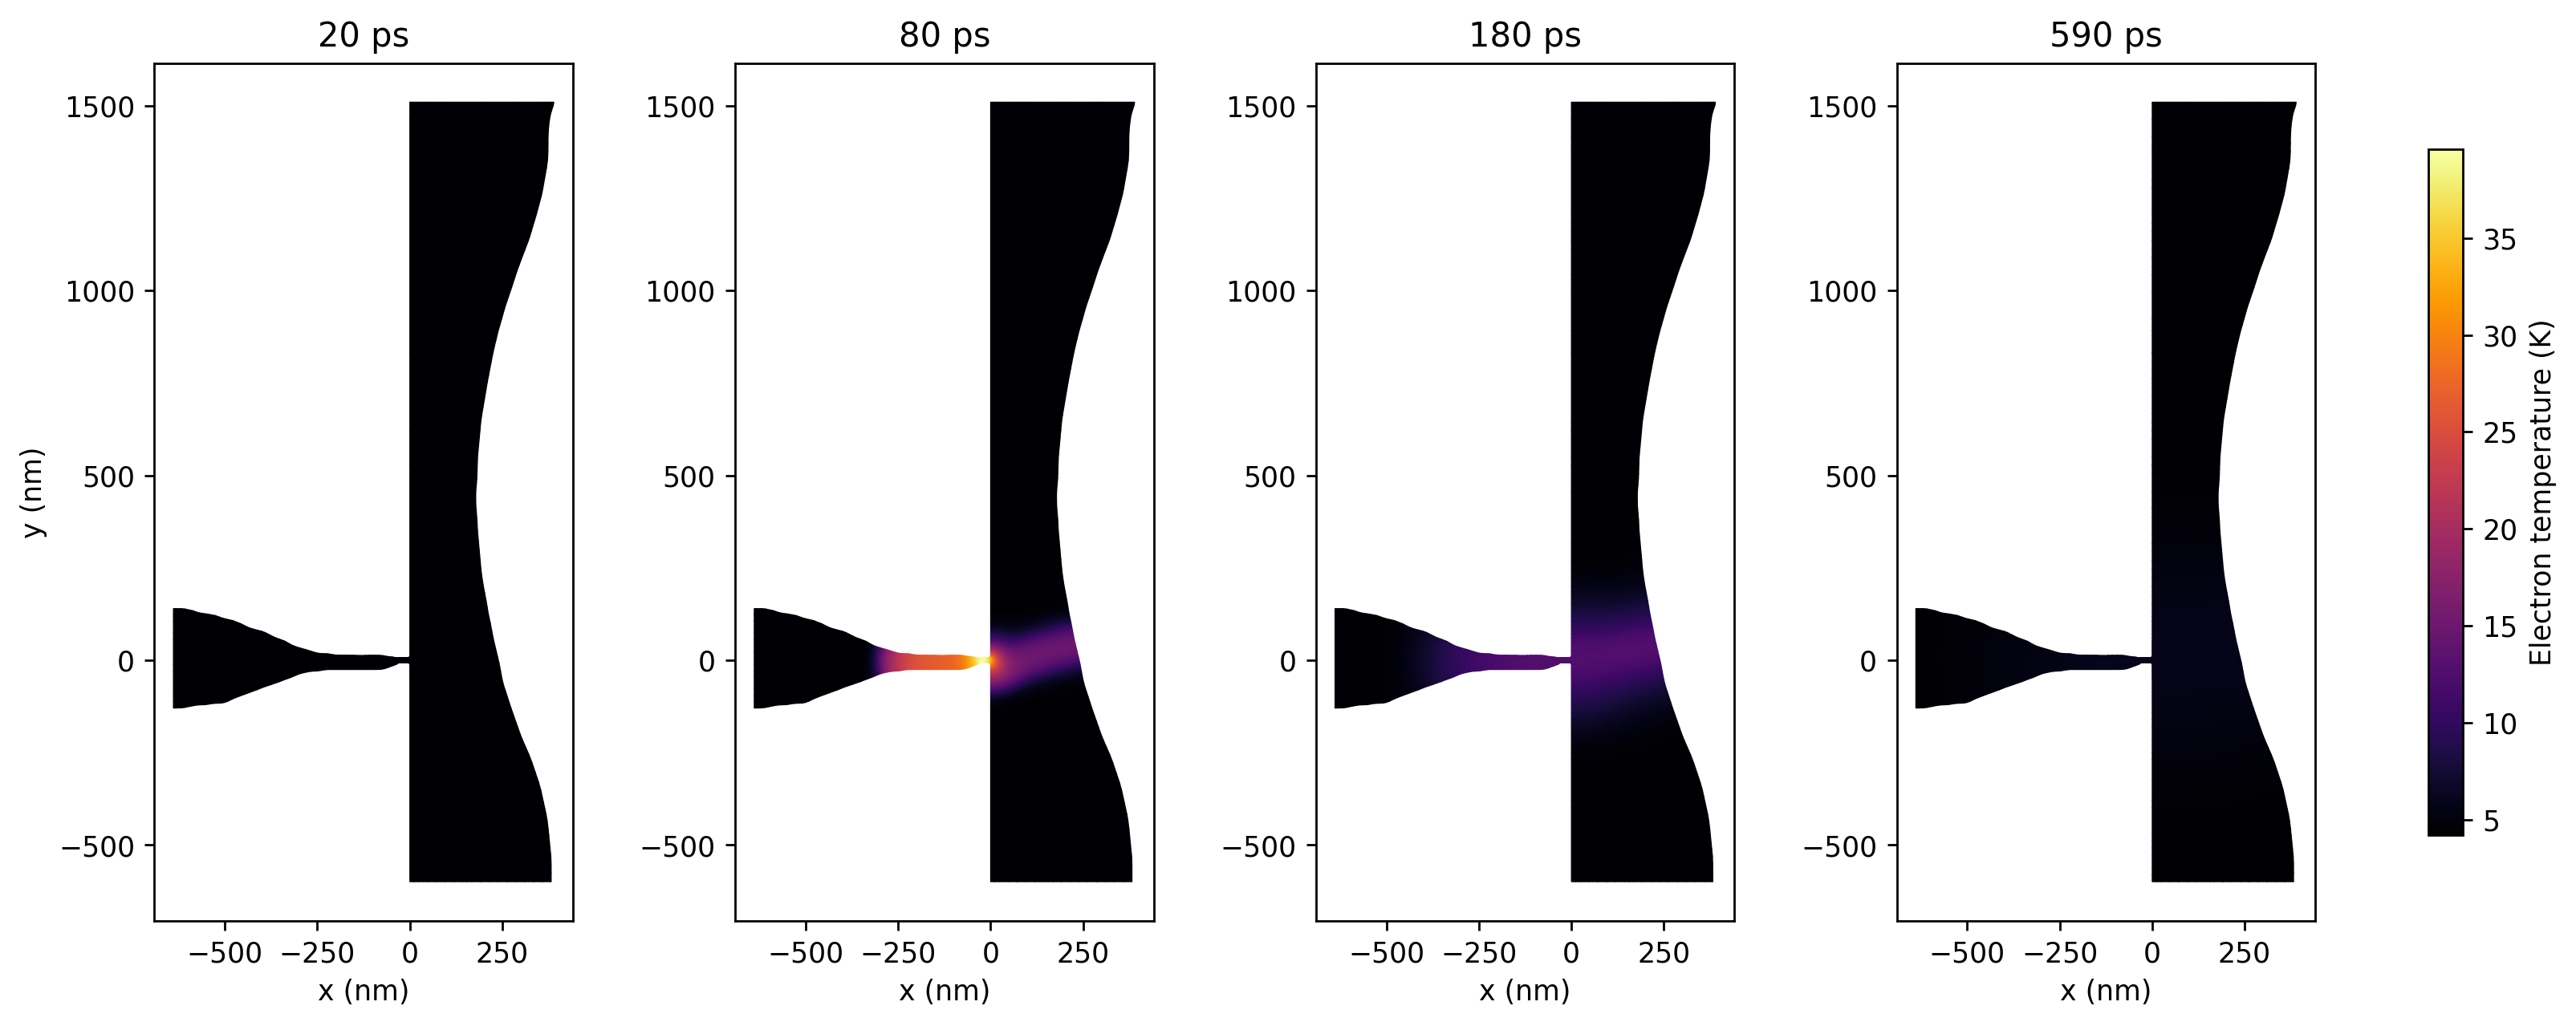

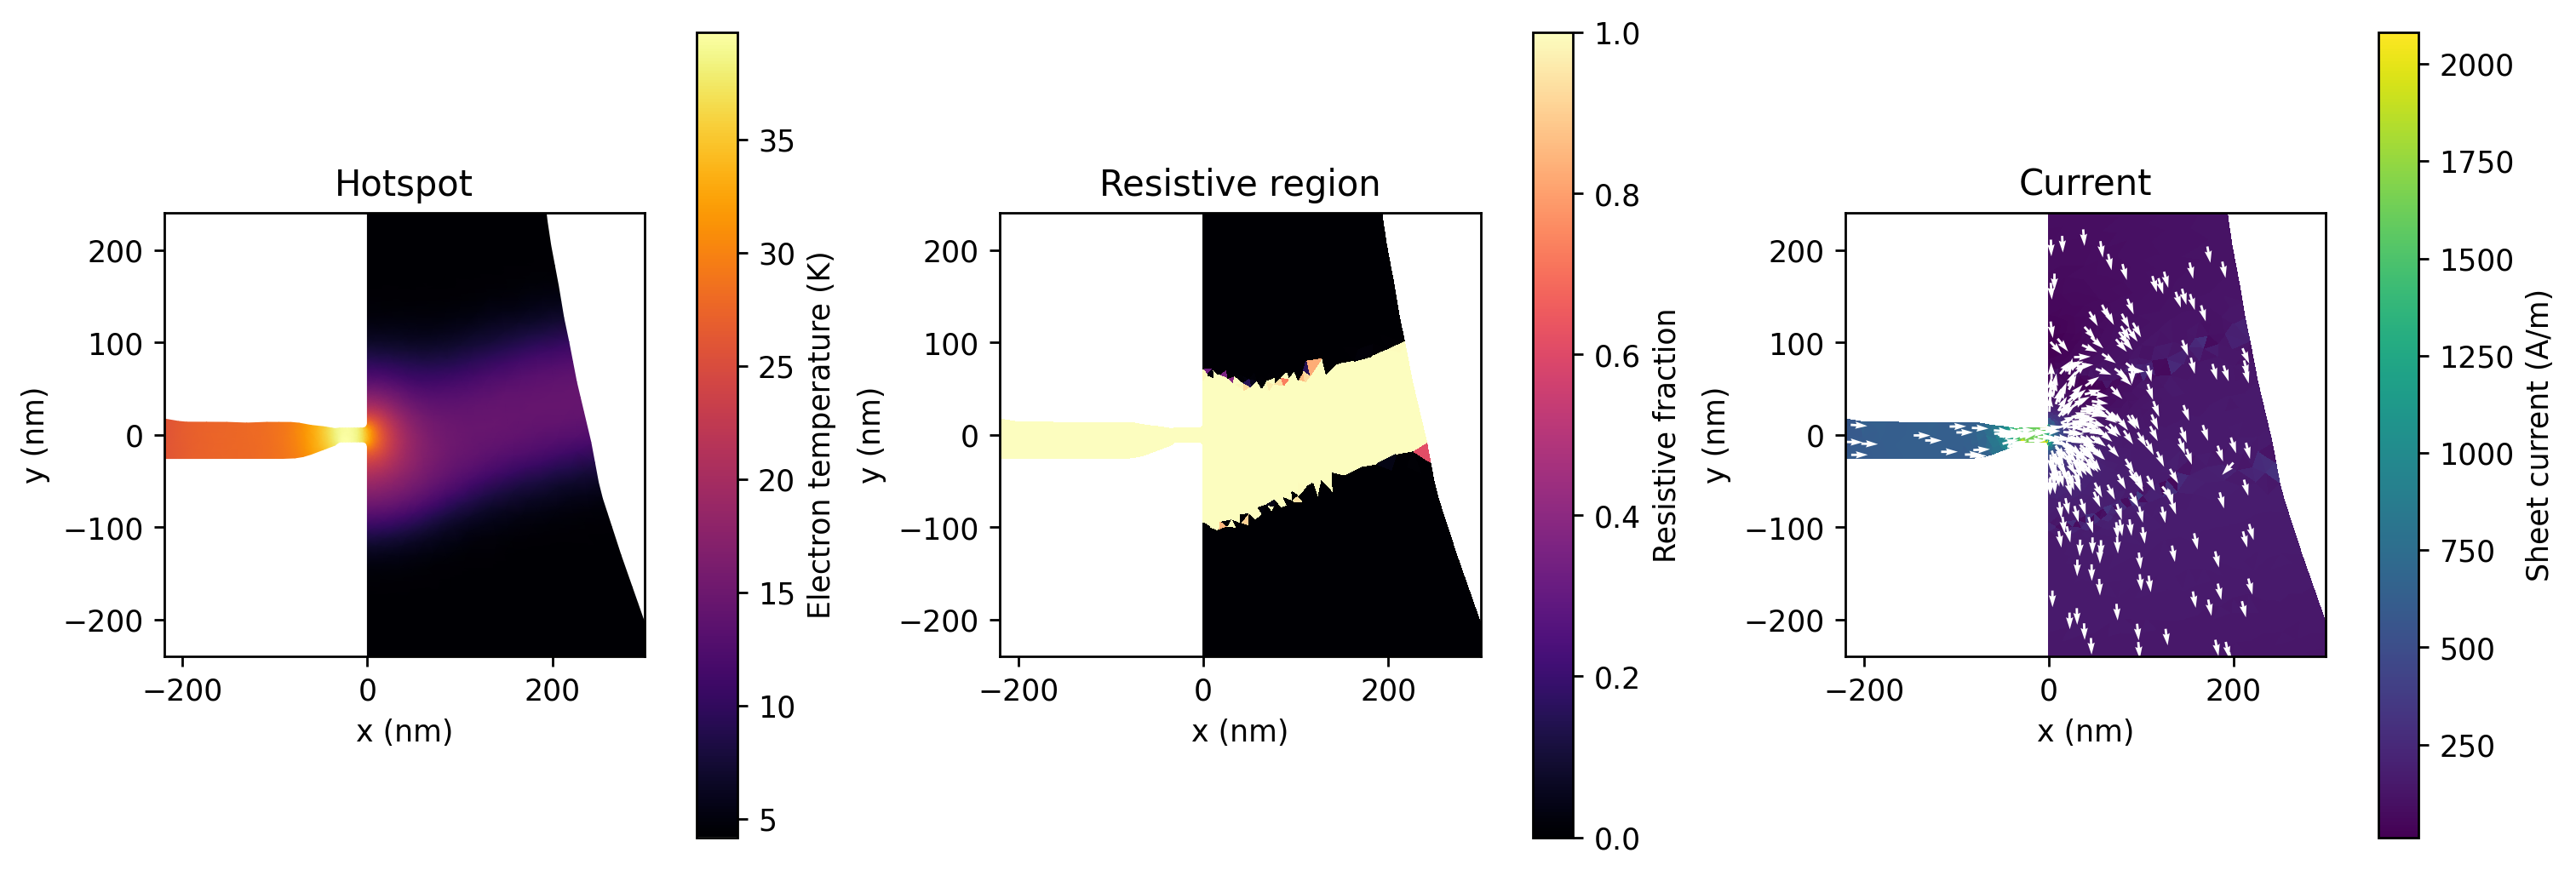

In [9]:
# --- Four thermal snapshots ---
selected = results[1]
requested_times = [25.0, 85.0, 180.0, min(590.0, STOP_PS - FIELD_INTERVAL_PS)]
snapshot_times = np.array([frame[0] for frame in selected["snapshots"]])
frame_indices = [
    int(np.argmin(abs(snapshot_times - time_ps * 1e-12))) for time_ps in requested_times
]
frames = [selected["snapshots"][index] for index in frame_indices]
temperature_max = max(frame[1].max() for frame in frames)
fig, axes = plt.subplots(1, 4, figsize=(13, 5), dpi=DPI, layout="constrained")
for ax, frame in zip(axes, frames):
    now, electron_temperature, resistive_fraction, sheet_current = frame
    image = ax.tripcolor(
        tri_plot,
        electron_temperature,
        shading="gouraud",
        cmap="inferno",
        vmin=Tb,
        vmax=temperature_max,
    )
    ax.set_aspect("equal")
    ax.set(xlabel="x (nm)", title=f"{now * 1e12:.0f} ps")
axes[0].set_ylabel("y (nm)")
fig.colorbar(image, ax=axes, label="Electron temperature (K)", shrink=0.8)
for text in fig.findobj(match=Text):
    text.set_fontfamily("DejaVu Sans")
    text.set_fontweight("normal")
plt.show()

# --- Peak hotspot and normalized current directions ---
peak_index = int(np.argmax([frame[1].max() for frame in selected["snapshots"]]))
now, electron_temperature, resistive_fraction, sheet_current = selected["snapshots"][
    peak_index
]
centers_nm = mesh.p[:, mesh.t].mean(axis=1) * 1e9
pick = (abs(centers_nm[0]) < 220) & (abs(centers_nm[1]) < 240)
arrows = np.flatnonzero(pick)[::8]
norm = np.linalg.norm(sheet_current[:, arrows], axis=0)
directions = sheet_current[:, arrows] / np.maximum(norm, 1e-30)
fig, axes = plt.subplots(1, 3, figsize=(12, 4), dpi=DPI, layout="constrained")
image = axes[0].tripcolor(
    tri_plot, electron_temperature, shading="gouraud", cmap="inferno"
)
fig.colorbar(image, ax=axes[0], label="Electron temperature (K)")
image = axes[1].tripcolor(
    tri_plot, facecolors=resistive_fraction, cmap="magma", vmin=0, vmax=1
)
fig.colorbar(image, ax=axes[1], label="Resistive fraction")
image = axes[2].tripcolor(
    tri_plot, facecolors=np.linalg.norm(sheet_current, axis=0), cmap="viridis"
)
axes[2].quiver(
    centers_nm[0, arrows],
    centers_nm[1, arrows],
    18 * directions[0],
    18 * directions[1],
    angles="xy",
    scale_units="xy",
    scale=1,
    color="white",
    width=0.005,
)
fig.colorbar(image, ax=axes[2], label="Sheet current (A/m)")
for ax, title in zip(axes, ("Hotspot", "Resistive region", "Current")):
    ax.set_aspect("equal")
    ax.set(
        xlim=(-220, 300),
        ylim=(-240, 240),
        xlabel="x (nm)",
        ylabel="y (nm)",
        title=title,
    )
for text in fig.findobj(match=Text):
    text.set_fontfamily("DejaVu Sans")
    text.set_fontweight("normal")
plt.show()

| Run | Peak positive output (mV) | Peak Te (K) | Joule energy (aJ) | Electrical residual | Thermal residual | Current residual |
|---|---:|---:|---:|---:|---:|---:|
| No gate | 3.4510 | 4.200 | 0.000 | 2.55e-14 | 7.86e-15 | 5.52e-16 |
| Gate pulse | 4.0547 | 39.783 | 90.625 | 9.24e-13 | 7.90e-15 | 8.26e-14 |
| Fourfold inductance | 4.2365 | 39.812 | 98.942 | 1.99e-13 | 7.31e-15 | 1.79e-14 |
| Half time step | 4.1592 | 39.778 | 91.458 | 3.93e-13 | 1.65e-14 | 4.11e-14 |

No-gate control: maximum pre-pulse temperature rise = 0.0001227 K
Residuals are normalized by each run's largest electrical power or by the channel bias current.
The thermal balance uses lagged effective heat capacities, matching the solved time step.
Time-step comparison through 180 ps:
  Voltage trace maximum relative difference: 22.69%
  Temperature-rise maximum relative difference: 9.51%
Decrease DT_PS when the reported changes exceed the accuracy needed for a quantitative comparison.


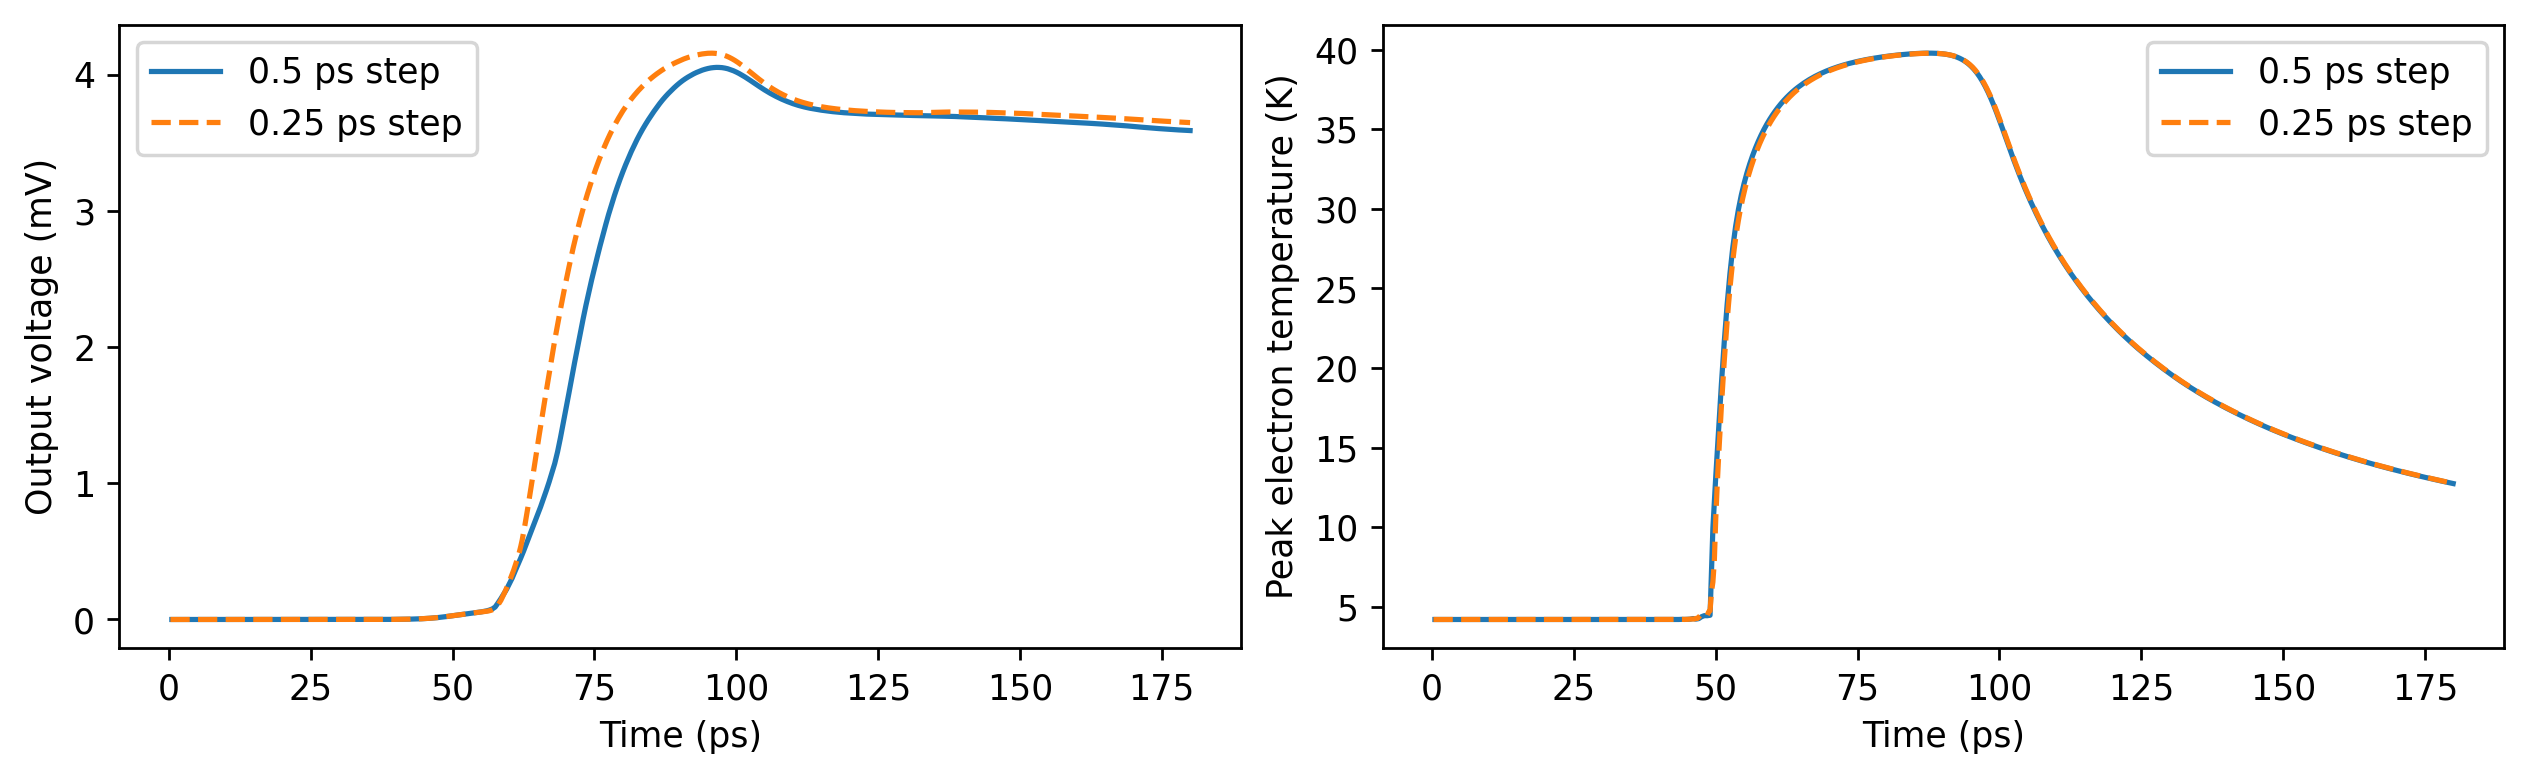

Peak output relative change: 2.51%


In [10]:
# --- Numerical checks and scenario summary ---
rows = [
    "| Run | Peak positive output (mV) | Peak Te (K) | Joule energy (aJ) | Electrical residual | Thermal residual | Current residual |",
    "|---|---:|---:|---:|---:|---:|---:|",
]
for result in results:
    data = result["data"]
    joule_energy = data[:, 6].sum() * result["dt_ps"] * 1e-12
    rows.append(
        f"| {result['name']} | {data[:, 3].max() * 1e3:.4f} | {data[:, 4].max():.3f} | {joule_energy * 1e18:.3f} | {result['electrical_residual']:.2e} | {result['thermal_residual']:.2e} | {result['current_residual']:.2e} |"
    )
    assert result["electrical_residual"] < 1e-5
    assert result["thermal_residual"] < 1e-5
    assert result["current_residual"] < 1e-5
display(Markdown("\n".join(rows)))
control = results[0]["data"]
pre_gate = control[:, 0] < GATE_START_PS * 1e-12
print(
    f"No-gate control: maximum pre-pulse temperature rise = {(control[pre_gate, 4] - Tb).max():.4g} K"
)
print(
    "Residuals are normalized by each run's largest electrical power or by the channel bias current."
)
print(
    "The thermal balance uses lagged effective heat capacities, matching the solved time step."
)

if VERIFY_TIME_STEP:
    fine = results[-1]["data"]
    coarse = results[1]["data"]
    sample = coarse[:, 0] <= fine[-1, 0]
    fine_voltage = np.interp(coarse[sample, 0], fine[:, 0], fine[:, 3])
    fine_temperature = np.interp(coarse[sample, 0], fine[:, 0], fine[:, 4])
    voltage_scale = max(np.abs(fine_voltage).max(), 1e-12)
    temperature_scale = max((fine_temperature - Tb).max(), 1e-12)
    voltage_change = np.max(abs(coarse[sample, 3] - fine_voltage)) / voltage_scale
    temperature_change = (
        np.max(abs(coarse[sample, 4] - fine_temperature)) / temperature_scale
    )
    print(f"Time-step comparison through {fine[-1, 0] * 1e12:g} ps:")
    print(f"  Voltage trace maximum relative difference: {voltage_change:.2%}")
    print(f"  Temperature-rise maximum relative difference: {temperature_change:.2%}")
    print(
        "Decrease DT_PS when the reported changes exceed the accuracy needed for a quantitative comparison."
    )
    fig, axes = plt.subplots(1, 2, figsize=(10, 3), dpi=DPI, layout="constrained")
    for ax, col, scale, label in (
        (axes[0], 3, 1e3, "Output voltage (mV)"),
        (axes[1], 4, 1.0, "Peak electron temperature (K)"),
    ):
        ax.plot(
            coarse[sample, 0] * 1e12,
            coarse[sample, col] * scale,
            label=f"{DT_PS:g} ps step",
        )
        ax.plot(
            fine[:, 0] * 1e12,
            fine[:, col] * scale,
            linestyle="--",
            label=f"{DT_PS / 2:g} ps step",
        )
        ax.set(xlabel="Time (ps)", ylabel=label)
        ax.legend()
    for text in fig.findobj(match=Text):
        text.set_fontfamily("DejaVu Sans")
        text.set_fontweight("normal")
    plt.show()

# Peak-output sensitivity uses the same pre-reset observation window.
if VERIFY_TIME_STEP:
    coarse_peak = coarse[sample, 3].max()
    fine_peak = fine[:, 3].max()
    print(f"Peak output relative change: {abs(coarse_peak / fine_peak - 1):.2%}")


In [11]:
# --- In-memory GDSII export ---
gds_buffer = io.BytesIO()
layout.write_gds(gds_buffer, unit=1e-6, precision=1e-10, cellname="NTRON_SEM_NBN")
gds_bytes = gds_buffer.getvalue()
assert len(gds_bytes) > 100
gds_base64 = base64.b64encode(gds_bytes).decode("ascii")
display(
    HTML(
        f'<a download="Nanocryotron_SEM_PHIDL.gds" href="data:application/octet-stream;base64,{gds_base64}" style="display:inline-block;padding:10px 16px;border-radius:6px;background:#075da8;color:white;text-decoration:none">Download PHIDL GDSII</a>'
    )
)
print(
    f"{len(gds_bytes):,} GDSII bytes; superconducting material on layer 1, datatype 0; coordinates in micrometres."
)
print(
    "The exported polygon is the same simplified outline used for the finite element mesh."
)

1,216 GDSII bytes; superconducting material on layer 1, datatype 0; coordinates in micrometres.
The exported polygon is the same simplified outline used for the finite element mesh.
